In [8]:
import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('/kaggle/input/competitions/home-credit-default-risk')

/kaggle/input/competitions/home-credit-default-risk/sample_submission.csv
/kaggle/input/competitions/home-credit-default-risk/bureau_balance.csv
/kaggle/input/competitions/home-credit-default-risk/POS_CASH_balance.csv
/kaggle/input/competitions/home-credit-default-risk/application_train.csv
/kaggle/input/competitions/home-credit-default-risk/HomeCredit_columns_description.csv
/kaggle/input/competitions/home-credit-default-risk/application_test.csv
/kaggle/input/competitions/home-credit-default-risk/previous_application.csv
/kaggle/input/competitions/home-credit-default-risk/credit_card_balance.csv
/kaggle/input/competitions/home-credit-default-risk/installments_payments.csv
/kaggle/input/competitions/home-credit-default-risk/bureau.csv


## 1. Business Problem

Financial institutions need to assess the credit risk of loan applicants
before approving loans. Incorrectly approving a high-risk applicant can
result in financial losses, while incorrectly rejecting a low-risk applicant
can result in lost business.

This project develops a machine learning model to estimate the probability
that a current loan applicant will default using demographic, financial,
employment, and historical credit information.

## 2. Project Objective

The objectives are to:

1. Understand customer characteristics through EDA and customer profiling.
2. Integrate current application data with historical credit information.
3. Handle missing values, duplicates, outliers, and class imbalance.
4. Engineer meaningful customer-level risk features.
5. Compare multiple classification algorithms.
6. Tune the best-performing model.
7. Explain the final model using feature importance and SHAP.
8. Translate model outputs into actionable business recommendations.

# Home Credit Default Risk Prediction

## Objective

Predict whether a loan applicant is likely to default using demographic,
financial, employment, and historical credit information.

## Business Problem

Financial institutions need to identify customers who are likely to default
so that they can make better lending and risk-management decisions.

In [11]:
DATA_PATH = "/kaggle/input/competitions/home-credit-default-risk/"

os.listdir(DATA_PATH)

['sample_submission.csv',
 'bureau_balance.csv',
 'POS_CASH_balance.csv',
 'application_train.csv',
 'HomeCredit_columns_description.csv',
 'application_test.csv',
 'previous_application.csv',
 'credit_card_balance.csv',
 'installments_payments.csv',
 'bureau.csv']

In [17]:
#inspecting the dataset sizes
for filename in os.listdir(DATA_PATH):
    filepath = os.path.join(DATA_PATH, filename)
    size_mb = os.path.getsize(filepath)/(1024**2)
    print(f"{filename:30} {size_mb:,.2f}MB")

sample_submission.csv          0.51MB
bureau_balance.csv             358.19MB
POS_CASH_balance.csv           374.51MB
application_train.csv          158.44MB
HomeCredit_columns_description.csv 0.04MB
application_test.csv           25.34MB
previous_application.csv       386.21MB
credit_card_balance.csv        404.91MB
installments_payments.csv      689.62MB
bureau.csv                     162.14MB


In [18]:
#loading the dataset we needed
application = pd.read_csv(f"{DATA_PATH}/application_train.csv")
application.shape

(307511, 122)

In [19]:
application.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
application.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [21]:
application.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [24]:
application.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [25]:
# customer profiling + EDA:
#--> who are the customers?
#--> what does income distribution look like
#--> age distribution
#--> education groups and most common
#--> how employment relate to default?
#--> Which customer characteristics appear associated with default?
#--> How severe is the class imbalance?

In [28]:
import seaborn as sns
sns.set_theme(style="whitegrid")

In [30]:
target_count = application["TARGET"].value_counts()
print(target_count)

TARGET
0    282686
1     24825
Name: count, dtype: int64


In [31]:
target_percentage = application["TARGET"].value_counts(normalize=True)*100
print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


Text(0, 0.5, 'no of applications')

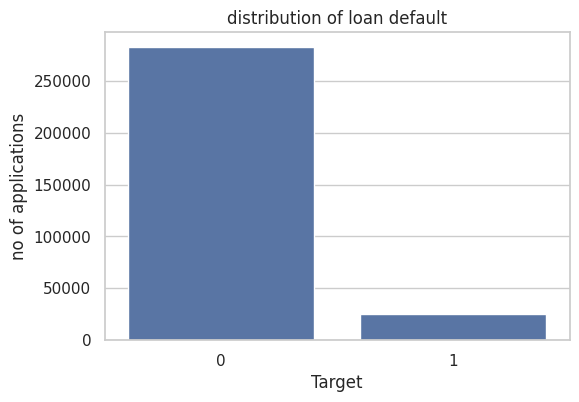

In [32]:
#visualizing the data
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
sns.countplot(data=application, x="TARGET")
plt.title("distribution of loan default")
plt.xlabel("Target")
plt.ylabel("no of applications")

In [50]:
#fixing days_birth column from negative values to uable data
application["AGE_YEARS"] = -application["DAYS_BIRTH"] / 365.25

In [51]:
application["AGE_YEARS"].describe()

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: AGE_YEARS, dtype: float64

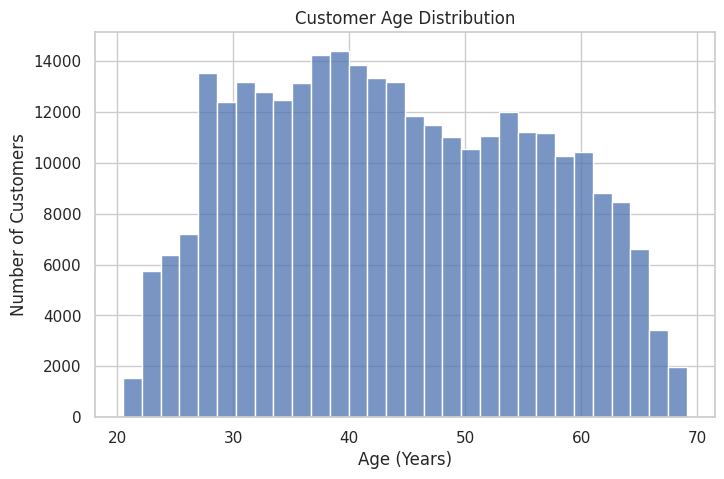

In [52]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=application,
    x="AGE_YEARS",
    bins=30
)

plt.title("Customer Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")

plt.show()

In [53]:
#creating age groups
application["AGE_GROUP"] = pd.cut(
    application["AGE_YEARS"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

In [54]:
age_default_rate = (
    application
    .groupby("AGE_GROUP", observed=True)["TARGET"]
    .mean()
    * 100
)

age_default_rate

AGE_GROUP
18-25    12.294613
26-35    10.660095
36-45     8.408398
46-55     7.046588
56-65     5.421169
65+       3.656679
Name: TARGET, dtype: float64

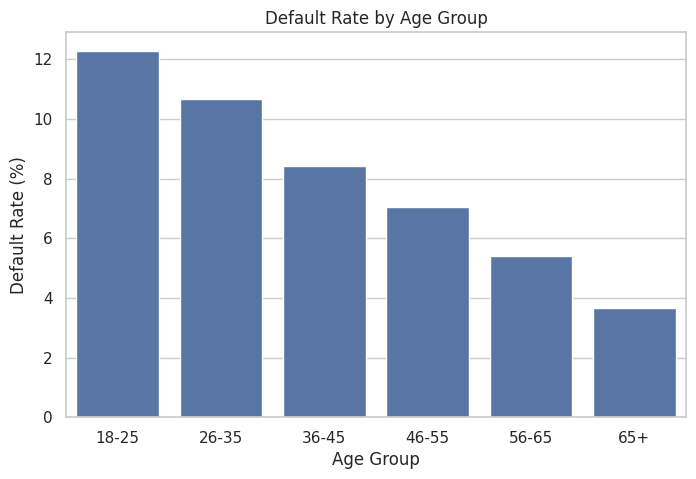

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_default_rate.index,
    y=age_default_rate.values
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.show()

AGE_GROUP
NaN      307511
26-35         0
18-25         0
36-45         0
46-55         0
56-65         0
65+           0
Name: count, dtype: int64

In [58]:
#income distribution
#examining customers income
application["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

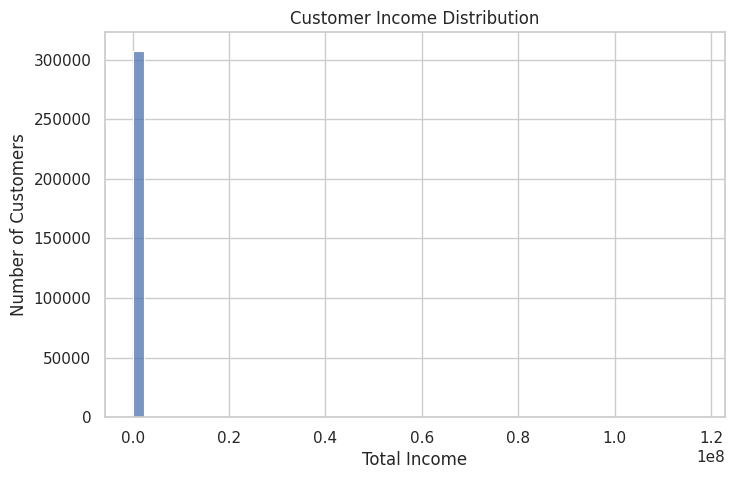

In [59]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=application,
    x="AMT_INCOME_TOTAL",
    bins=50
)

plt.title("Customer Income Distribution")
plt.xlabel("Total Income")
plt.ylabel("Number of Customers")

plt.show()

In [60]:
application["AMT_INCOME_TOTAL"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
1%       4.500000e+04
5%       6.750000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
95%      3.375000e+05
99%      4.725000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [61]:
application[
    ["SK_ID_CURR", "AMT_INCOME_TOTAL", "TARGET"]
].sort_values(
    "AMT_INCOME_TOTAL",
    ascending=False
).head(10)

,SK_ID_CURR,AMT_INCOME_TOTAL,TARGET
12840,114967,117000000.0,1
203693,336147,18000090.0,0
246858,385674,13500000.0,0
77768,190160,9000000.0,0
131127,252084,6750000.0,0
103006,219563,4500000.0,0
287463,432980,4500000.0,0
187833,317748,4500000.0,0
204564,337151,4500000.0,0
181698,310601,3950059.5,0


In [62]:
#loan amount distribution
application["AMT_CREDIT"].describe()

count    3.075110e+05
mean     5.990260e+05
std      4.024908e+05
min      4.500000e+04
25%      2.700000e+05
50%      5.135310e+05
75%      8.086500e+05
max      4.050000e+06
Name: AMT_CREDIT, dtype: float64

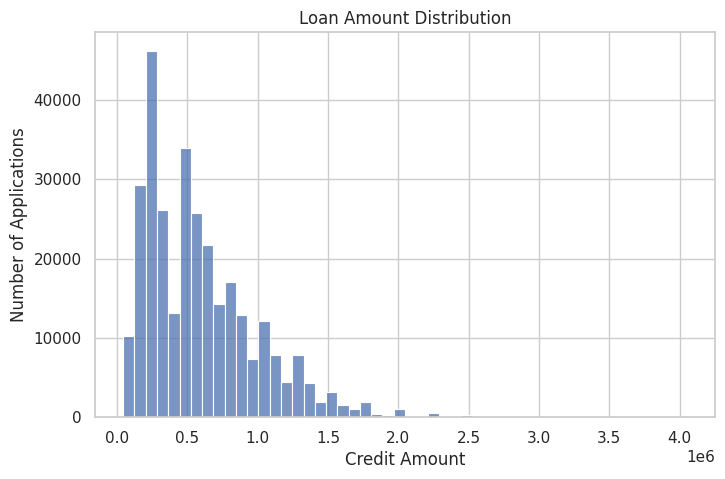

In [63]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=application,
    x="AMT_CREDIT",
    bins=50
)

plt.title("Loan Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Number of Applications")

plt.show()

In [64]:
#income to loan ratio --> How large is the loan relative to the applicant's income?
application["CREDIT_TO_INCOME"] = (
    application["AMT_CREDIT"] /
    application["AMT_INCOME_TOTAL"]
)

In [65]:
application["CREDIT_TO_INCOME"].describe()

count    307511.000000
mean          3.957570
std           2.689728
min           0.004808
25%           2.018667
50%           3.265067
75%           5.159880
max          84.736842
Name: CREDIT_TO_INCOME, dtype: float64

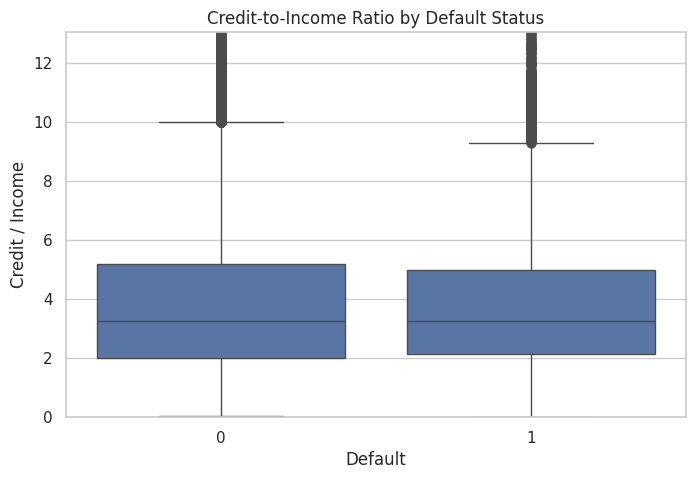

In [66]:
#Credit-to-income ratio vs default

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=application,
    x="TARGET",
    y="CREDIT_TO_INCOME"
)

plt.ylim(
    0,
    application["CREDIT_TO_INCOME"].quantile(0.99)
)

plt.title("Credit-to-Income Ratio by Default Status")
plt.xlabel("Default")
plt.ylabel("Credit / Income")

plt.show()

In [67]:
    education_counts = (
    application["NAME_EDUCATION_TYPE"]
    .value_counts()
)

education_counts

NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

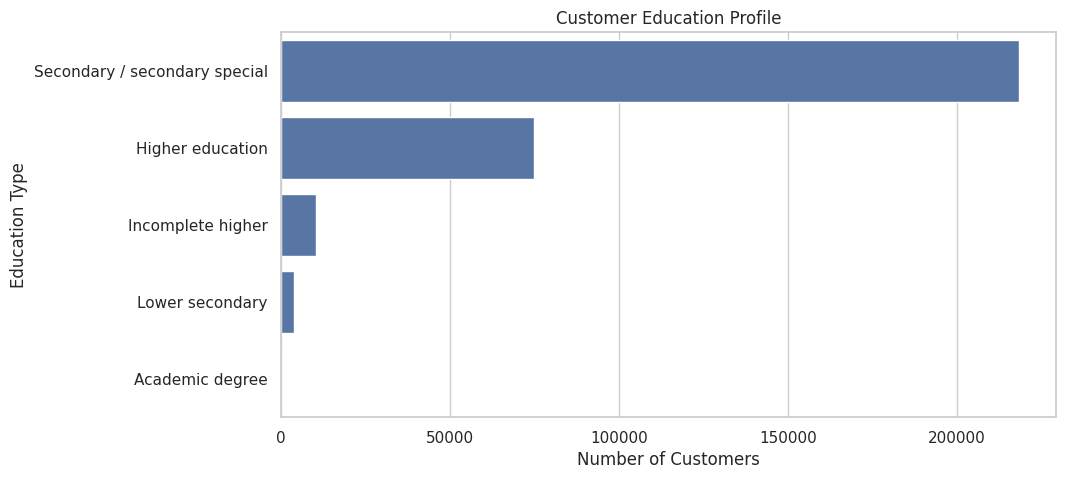

In [68]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=application,
    y="NAME_EDUCATION_TYPE",
    order=education_counts.index
)

plt.title("Customer Education Profile")
plt.xlabel("Number of Customers")
plt.ylabel("Education Type")

plt.show()

In [69]:
education_default_rate = (
    application
    .groupby("NAME_EDUCATION_TYPE")["TARGET"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

education_default_rate

NAME_EDUCATION_TYPE
Lower secondary                  10.927673
Secondary / secondary special     8.939929
Incomplete higher                 8.484966
Higher education                  5.355115
Academic degree                   1.829268
Name: TARGET, dtype: float64

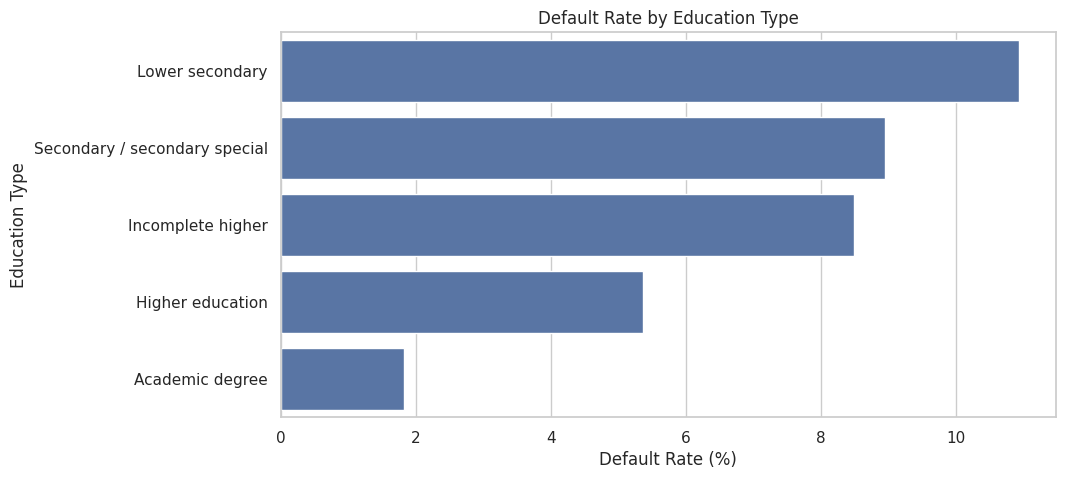

In [70]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=education_default_rate.values,
    y=education_default_rate.index
)

plt.title("Default Rate by Education Type")
plt.xlabel("Default Rate (%)")
plt.ylabel("Education Type")

plt.show()

In [73]:
#converting em days to emp-years
application["EMPLOYMENT_YEARS"] = (
    -application["DAYS_EMPLOYED"] / 365.25
)

In [74]:
application["EMPLOYMENT_YEARS"].describe()

count    307511.000000
mean       -174.716074
std         386.791969
min        -999.980835
25%           0.791239
50%           3.321013
75%           7.556468
max          49.040383
Name: EMPLOYMENT_YEARS, dtype: float64

In [77]:
application[
    ["SK_ID_CURR", "DAYS_EMPLOYED", "EMPLOYMENT_YEARS", "TARGET"]
].sort_values(
    "DAYS_EMPLOYED",
    ascending=True
).head(20)

,SK_ID_CURR,DAYS_EMPLOYED,EMPLOYMENT_YEARS,TARGET
280994,425566,-17912,49.040383,0
273069,416545,-17583,48.139630,0
208899,342112,-17546,48.038330,0
35191,140766,-17531,47.997262,0
234168,371247,-17522,47.972621,0
142446,265162,-17170,47.008898,0
143265,266124,-17139,46.924025,0
296917,443997,-16852,46.138261,0
39095,145275,-16849,46.130048,0
249164,388307,-16836,46.094456,0


In [78]:
application["EMPLOYMENT_GROUP"] = pd.cut(
    application["EMPLOYMENT_YEARS"],
    bins=[-np.inf, 1, 3, 5, 10, np.inf],
    labels=[
        "<1 year",
        "1-3 years",
        "3-5 years",
        "5-10 years",
        "10+ years"
    ]
)

In [79]:
employment_default_rate = (
    application
    .groupby("EMPLOYMENT_GROUP", observed=True)["TARGET"]
    .mean()
    * 100
)

employment_default_rate

EMPLOYMENT_GROUP
<1 year        7.270023
1-3 years     11.073334
3-5 years      9.671229
5-10 years     7.371553
10+ years      5.185622
Name: TARGET, dtype: float64

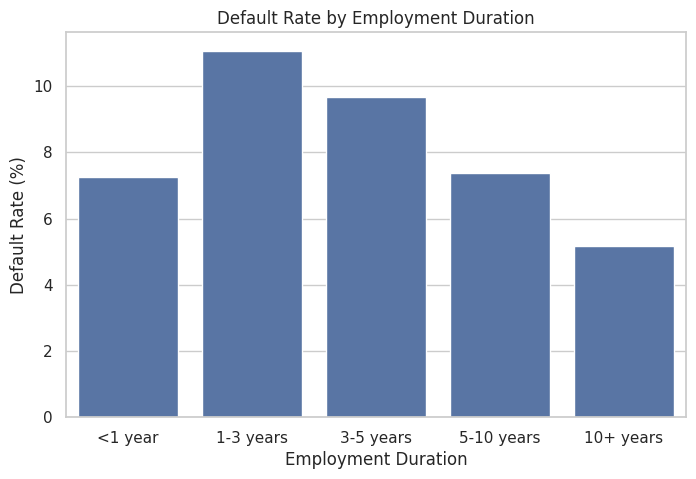

In [80]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=employment_default_rate.index,
    y=employment_default_rate.values
)

plt.title("Default Rate by Employment Duration")
plt.xlabel("Employment Duration")
plt.ylabel("Default Rate (%)")

plt.show()

In [81]:
application[
    [
        "CNT_CHILDREN",
        "CNT_FAM_MEMBERS"
    ]
].describe()

,CNT_CHILDREN,CNT_FAM_MEMBERS
count,307511.000000,307509.000000
mean,0.417052,2.152665
std,0.722121,0.910682
min,0.000000,1.000000
25%,0.000000,2.000000
50%,0.000000,2.000000
75%,1.000000,3.000000
max,19.000000,20.000000


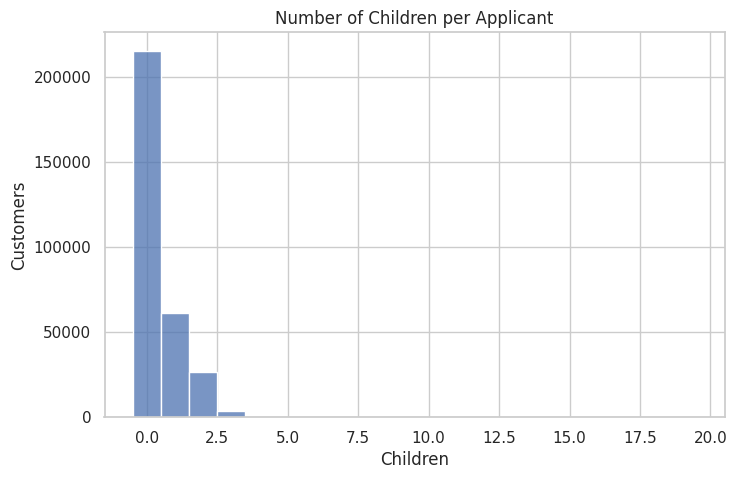

In [82]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=application,
    x="CNT_CHILDREN",
    discrete=True
)

plt.title("Number of Children per Applicant")
plt.xlabel("Children")
plt.ylabel("Customers")

plt.show()

In [83]:
application["OCCUPATION_TYPE"].value_counts(dropna=False) #including missing val's

OCCUPATION_TYPE
NaN                      96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

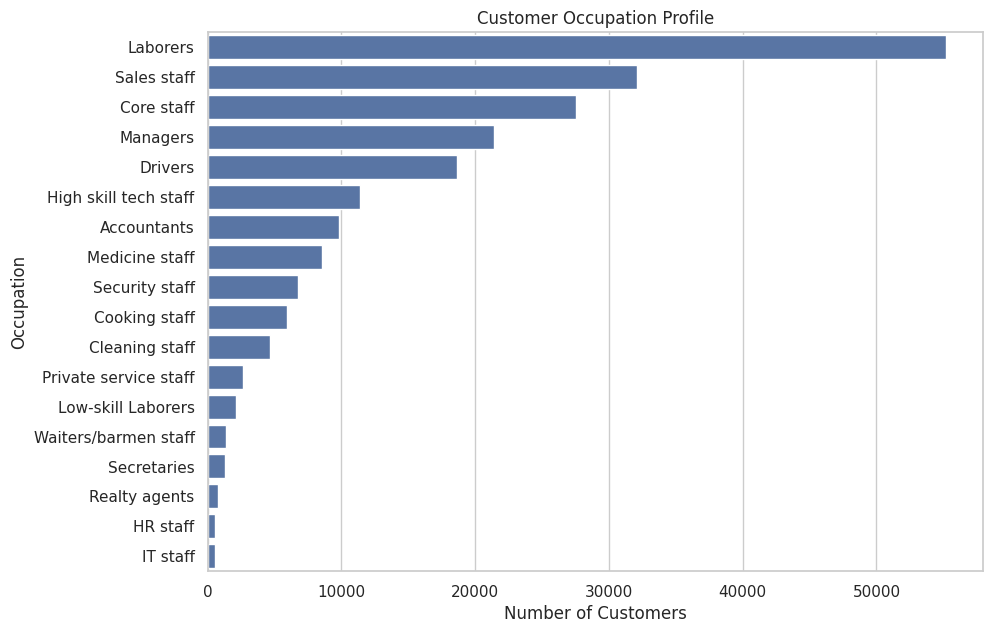

In [84]:
plt.figure(figsize=(10, 7))

occupation_counts = application["OCCUPATION_TYPE"].value_counts()

sns.barplot(
    x=occupation_counts.values,
    y=occupation_counts.index
)

plt.title("Customer Occupation Profile")
plt.xlabel("Number of Customers")
plt.ylabel("Occupation")

plt.show()

In [85]:
#external credit-related scores.
application[
    [
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ]
].describe()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,134133.000000,3.068510e+05,246546.000000
mean,0.502130,5.143927e-01,0.510853
std,0.211062,1.910602e-01,0.194844
min,0.014568,8.173617e-08,0.000527
25%,0.334007,3.924574e-01,0.370650
50%,0.505998,5.659614e-01,0.535276
75%,0.675053,6.636171e-01,0.669057
max,0.962693,8.549997e-01,0.896010


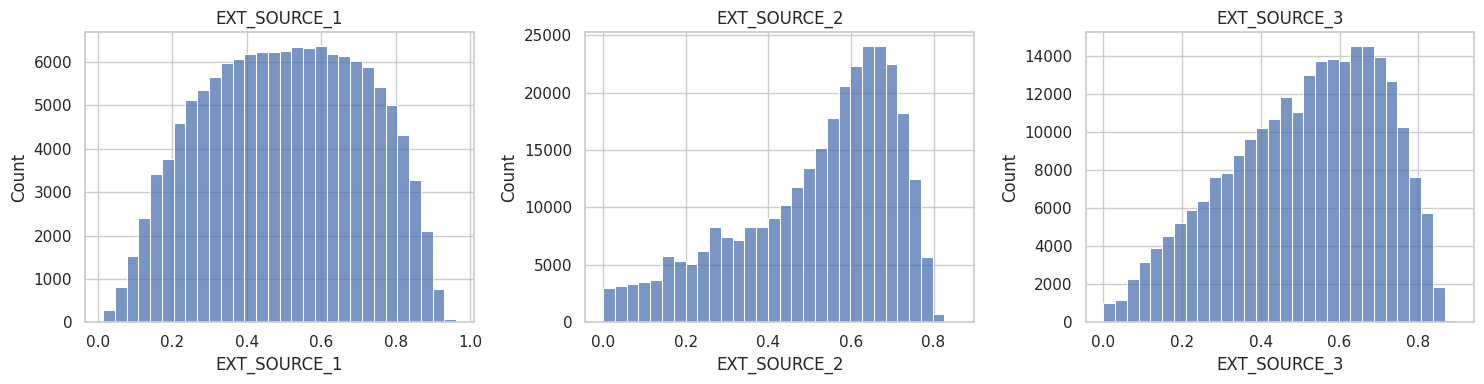

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    application["EXT_SOURCE_1"],
    bins=30,
    ax=axes[0]
)

sns.histplot(
    application["EXT_SOURCE_2"],
    bins=30,
    ax=axes[1]
)

sns.histplot(
    application["EXT_SOURCE_3"],
    bins=30,
    ax=axes[2]
)

axes[0].set_title("EXT_SOURCE_1")
axes[1].set_title("EXT_SOURCE_2")
axes[2].set_title("EXT_SOURCE_3")

plt.tight_layout()
plt.show()

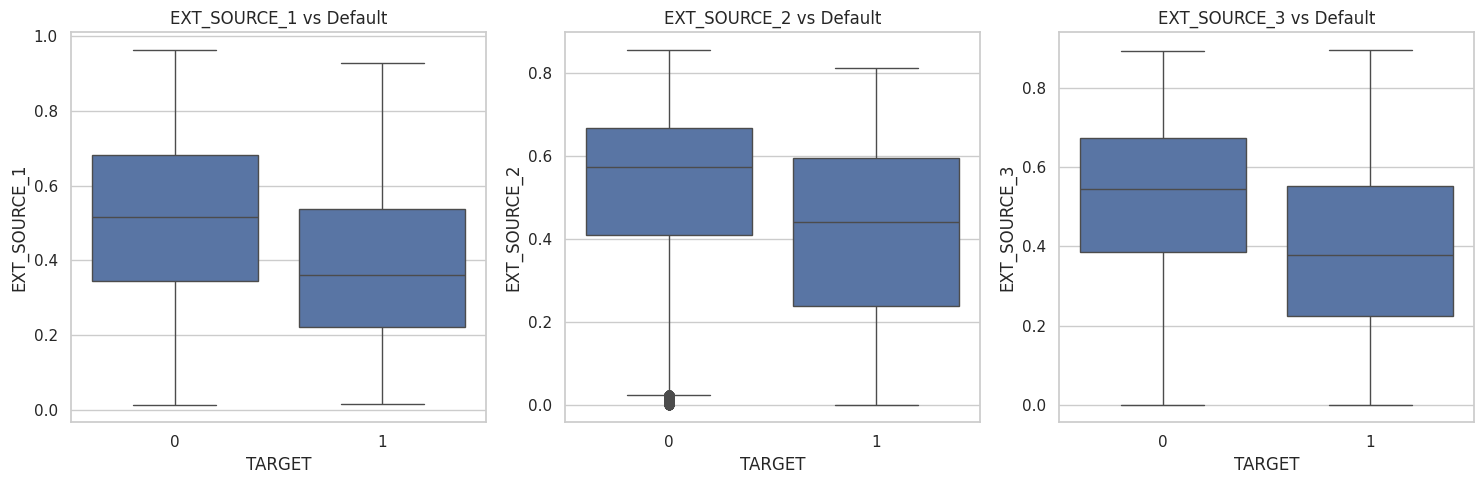

In [90]:
#External scores vs default
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(
    data=application,
    x="TARGET",
    y="EXT_SOURCE_1",
    ax=axes[0]
)

sns.boxplot(
    data=application,
    x="TARGET",
    y="EXT_SOURCE_2",
    ax=axes[1]
)

sns.boxplot(
    data=application,
    x="TARGET",
    y="EXT_SOURCE_3",
    ax=axes[2]
)

axes[0].set_title("EXT_SOURCE_1 vs Default")
axes[1].set_title("EXT_SOURCE_2 vs Default")
axes[2].set_title("EXT_SOURCE_3 vs Default")

plt.tight_layout()
plt.show()

In [91]:
#Create an EDA summary table

eda_summary = pd.DataFrame({
    "Metric": [
        "Number of applications",
        "Number of features",
        "Default count",
        "Non-default count",
        "Default rate"
    ],
    "Value": [
        len(application),
        application.shape[1],
        (application["TARGET"] == 1).sum(),
        (application["TARGET"] == 0).sum(),
        application["TARGET"].mean() * 100
    ]
})

eda_summary

,Metric,Value
0,Number of applications,307511.000000
1,Number of features,127.000000
2,Default count,24825.000000
3,Non-default count,282686.000000
4,Default rate,8.072882


In [93]:
#data cleaning 
#count missing values
missing_count = application.isnull().sum()

missing_count = missing_count[
    missing_count > 0
].sort_values(ascending=False)

missing_count.head(20)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

In [94]:
missing_percent = (
    application.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent.head(20)

COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MODE       68.354953
LIVINGAPARTMENTS_MEDI       68.354953
FLOORSMIN_MEDI              67.848630
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MODE               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
dtype: float64

In [95]:
missing_summary = pd.DataFrame({
    "Missing_Count": application.isnull().sum(),
    "Missing_Percentage": application.isnull().mean() * 100
})

missing_summary = (
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ]
    .sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

missing_summary.head(20)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


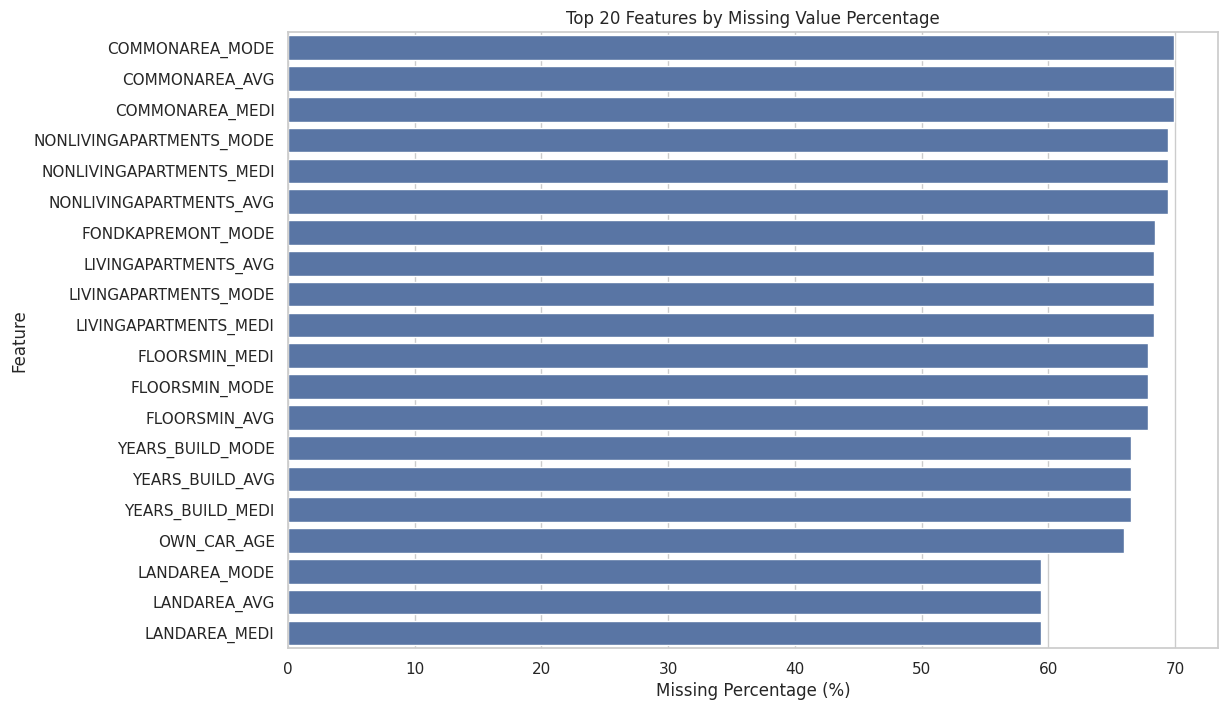

In [98]:
top_missing = missing_percent.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_missing.values,
    y=top_missing.index
)

plt.title("Top 20 Features by Missing Value Percentage")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Feature")

plt.show()

In [100]:
#Let's separate numerical and categorical columns.
numeric_missing = (
    application
    .select_dtypes(include=np.number)
    .isnull()
    .mean()
    .sort_values(ascending=False)
    * 100
)

categorical_missing = (
    application
    .select_dtypes(include="object")
    .isnull()
    .mean()
    .sort_values(ascending=False)
    * 100
)

print("Numerical:")
display(numeric_missing.head(10))

print("\nCategorical:")
display(categorical_missing.head(10))

Numerical:


COMMONAREA_AVG              69.872297
COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_AVG     69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
dtype: float64


Categorical:


FONDKAPREMONT_MODE     68.386172
WALLSMATERIAL_MODE     50.840783
HOUSETYPE_MODE         50.176091
EMERGENCYSTATE_MODE    47.398304
OCCUPATION_TYPE        31.345545
NAME_TYPE_SUITE         0.420148
FLAG_OWN_CAR            0.000000
NAME_CONTRACT_TYPE      0.000000
NAME_FAMILY_STATUS      0.000000
NAME_EDUCATION_TYPE     0.000000
dtype: float64

In [101]:
application["EXT_SOURCE_1_MISSING"] = (
    application["EXT_SOURCE_1"].isnull().astype(int)
)

In [102]:
application.groupby(
    "EXT_SOURCE_1_MISSING"
)["TARGET"].mean() * 100

EXT_SOURCE_1_MISSING
0    7.495545
1    8.519535
Name: TARGET, dtype: float64

In [103]:
#counting duplicates
duplicate_rows = application.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [104]:
duplicate_ids = application["SK_ID_CURR"].duplicated().sum()

print("Duplicate SK_ID_CURR:", duplicate_ids)

Duplicate SK_ID_CURR: 0


In [105]:
application[
    [
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "AMT_GOODS_PRICE"
    ]
].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
)

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05
mean,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05
std,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05
min,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04
1%,4.500000e+04,7.641000e+04,6182.910000,6.750000e+04
5%,6.750000e+04,1.350000e+05,9000.000000,1.350000e+05
25%,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05
50%,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05
75%,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05
95%,3.375000e+05,1.350000e+06,53325.000000,1.305000e+06


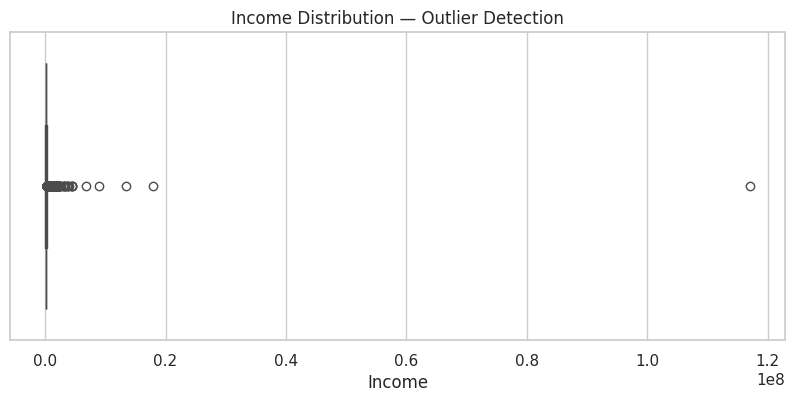

In [106]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=application["AMT_INCOME_TOTAL"]
)

plt.title("Income Distribution — Outlier Detection")
plt.xlabel("Income")

plt.show()

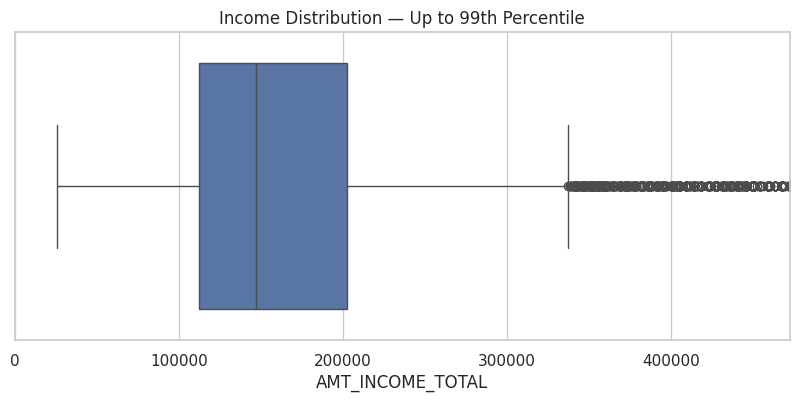

In [107]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=application["AMT_INCOME_TOTAL"]
)

plt.xlim(
    0,
    application["AMT_INCOME_TOTAL"].quantile(0.99)
)

plt.title("Income Distribution — Up to 99th Percentile")

plt.show()

In [108]:
#IQR 
Q1 = application["AMT_INCOME_TOTAL"].quantile(0.25)
Q3 = application["AMT_INCOME_TOTAL"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 112500.0
Q3: 202500.0
IQR: 90000.0
Lower bound: -22500.0
Upper bound: 337500.0


In [109]:
outlier_mask = (
    (application["AMT_INCOME_TOTAL"] < lower_bound) |
    (application["AMT_INCOME_TOTAL"] > upper_bound)
)

print("Number of income outliers:", outlier_mask.sum())
print(
    "Percentage:",
    outlier_mask.mean() * 100
)

Number of income outliers: 14035
Percentage: 4.564064374932929


In [110]:
application["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [111]:
application[
    application["DAYS_EMPLOYED"] == 365243
][
    [
        "SK_ID_CURR",
        "DAYS_EMPLOYED",
        "TARGET"
    ]
].head()

,SK_ID_CURR,DAYS_EMPLOYED,TARGET
8,100011,365243,0
11,100015,365243,0
23,100027,365243,0
38,100045,365243,0
43,100050,365243,0


In [112]:
(application["DAYS_EMPLOYED"] == 365243).sum()

np.int64(55374)

In [113]:
#class imbalance
class_counts = application["TARGET"].value_counts()

class_percent = (
    application["TARGET"]
    .value_counts(normalize=True)
    * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent
})

class_summary

,Count,Percentage
TARGET,,
0,282686,91.927118
1,24825,8.072882


Understand the Historical Tables

In [114]:
bureau_sample = pd.read_csv(
    f"{DATA_PATH}/bureau.csv",
    nrows=5
)

bureau_sample

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [115]:
bureau_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   SK_ID_CURR              5 non-null      int64  
 1   SK_ID_BUREAU            5 non-null      int64  
 2   CREDIT_ACTIVE           5 non-null      object 
 3   CREDIT_CURRENCY         5 non-null      object 
 4   DAYS_CREDIT             5 non-null      int64  
 5   CREDIT_DAY_OVERDUE      5 non-null      int64  
 6   DAYS_CREDIT_ENDDATE     4 non-null      float64
 7   DAYS_ENDDATE_FACT       1 non-null      float64
 8   AMT_CREDIT_MAX_OVERDUE  1 non-null      float64
 9   CNT_CREDIT_PROLONG      5 non-null      int64  
 10  AMT_CREDIT_SUM          5 non-null      float64
 11  AMT_CREDIT_SUM_DEBT     2 non-null      float64
 12  AMT_CREDIT_SUM_LIMIT    0 non-null      float64
 13  AMT_CREDIT_SUM_OVERDUE  5 non-null      float64
 14  CREDIT_TYPE             5 non-null      object

In [116]:
bureau_sample.columns.tolist()

['SK_ID_CURR',
 'SK_ID_BUREAU',
 'CREDIT_ACTIVE',
 'CREDIT_CURRENCY',
 'DAYS_CREDIT',
 'CREDIT_DAY_OVERDUE',
 'DAYS_CREDIT_ENDDATE',
 'DAYS_ENDDATE_FACT',
 'AMT_CREDIT_MAX_OVERDUE',
 'CNT_CREDIT_PROLONG',
 'AMT_CREDIT_SUM',
 'AMT_CREDIT_SUM_DEBT',
 'AMT_CREDIT_SUM_LIMIT',
 'AMT_CREDIT_SUM_OVERDUE',
 'CREDIT_TYPE',
 'DAYS_CREDIT_UPDATE',
 'AMT_ANNUITY']

In [117]:
#aggregation since the bureau dataset is larget
#going with chunks
def aggregate_bureau(file_path, chunk_size=100_000):
    
    chunks = []

    for chunk in pd.read_csv(
        file_path,
        chunksize=chunk_size
    ):
        #grouping by customer id
        chunk_agg = (
            chunk
            .groupby("SK_ID_CURR")
            .agg(
                bureau_account_count=("SK_ID_BUREAU", "count"),
                bureau_credit_mean=("AMT_CREDIT_SUM", "mean"),
                bureau_credit_max=("AMT_CREDIT_SUM", "max"),
                bureau_debt_mean=("AMT_CREDIT_SUM_DEBT", "mean"),
                bureau_overdue_max=("AMT_CREDIT_SUM_OVERDUE", "max"),
                bureau_days_credit_mean=("DAYS_CREDIT", "mean")
            )
            .reset_index()
        )
        
        chunks.append(chunk_agg)

    result = pd.concat(chunks, ignore_index=True)

    result = (
        result
        .groupby("SK_ID_CURR")
        .mean()
        .reset_index()
    )

    return result

In [118]:
bureau_features = aggregate_bureau(
    f"{DATA_PATH}/bureau.csv"
)

In [119]:
bureau_features.shape

(305811, 7)

In [121]:
bureau_features.head()

,SK_ID_CURR,bureau_account_count,bureau_credit_mean,bureau_credit_max,bureau_debt_mean,bureau_overdue_max,bureau_days_credit_mean
0,100001,7.000000,207623.571429,378000.0,85240.928571,0.0,-735.000000
1,100002,2.666667,191808.642500,217500.0,122890.500000,0.0,-967.611111
2,100003,4.000000,254350.125000,810000.0,0.000000,0.0,-1400.750000
3,100004,2.000000,94518.900000,94537.8,0.000000,0.0,-867.000000
4,100005,3.000000,219042.000000,568800.0,189469.500000,0.0,-190.666667


In [122]:
bureau_sample["CREDIT_ACTIVE"].value_counts()

CREDIT_ACTIVE
Active    4
Closed    1
Name: count, dtype: int64

In [123]:
bureau_features.head()

,SK_ID_CURR,bureau_account_count,bureau_credit_mean,bureau_credit_max,bureau_debt_mean,bureau_overdue_max,bureau_days_credit_mean
0,100001,7.000000,207623.571429,378000.0,85240.928571,0.0,-735.000000
1,100002,2.666667,191808.642500,217500.0,122890.500000,0.0,-967.611111
2,100003,4.000000,254350.125000,810000.0,0.000000,0.0,-1400.750000
3,100004,2.000000,94518.900000,94537.8,0.000000,0.0,-867.000000
4,100005,3.000000,219042.000000,568800.0,189469.500000,0.0,-190.666667


In [127]:
print("Rows:", len(bureau_features))
print("Unique customers:", bureau_features["SK_ID_CURR"].nunique())

Rows: 305811
Unique customers: 305811


In [128]:
bureau_balance_sample = pd.read_csv(
    f"{DATA_PATH}/bureau_balance.csv",
    nrows=5
)

bureau_balance_sample.head()

,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [131]:
bureau_balance_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   SK_ID_BUREAU    10 non-null     int64 
 1   MONTHS_BALANCE  10 non-null     int64 
 2   STATUS          10 non-null     object
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [129]:
bureau_balance_sample.columns.tolist()

['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

In [132]:
bureau_balance_sample["STATUS"].value_counts(dropna=False)

STATUS
C    9
0    1
Name: count, dtype: int64

In [133]:
#Build the account → customer mapping
bureau_mapping = pd.read_csv(
    f"{DATA_PATH}/bureau.csv",
    usecols=["SK_ID_CURR", "SK_ID_BUREAU"]
)

bureau_mapping.head()

,SK_ID_CURR,SK_ID_BUREAU
0,215354,5714462
1,215354,5714463
2,215354,5714464
3,215354,5714465
4,215354,5714466


In [134]:
bureau_mapping.shape

(1716428, 2)

In [135]:
bureau_mapping["SK_ID_BUREAU"].nunique()

1716428

In [137]:
CHUNK_SIZE=100_000

In [138]:
#Process the file in chunks
bureau_balance_chunks = []

for chunk in pd.read_csv(
    f"{DATA_PATH}/bureau_balance.csv",
    chunksize=CHUNK_SIZE
):
    
    chunk["delinquent"] = chunk["STATUS"].isin(
        ["1", "2", "3", "4", "5"]
    ).astype("int8")
    
    chunk["closed"] = (
        chunk["STATUS"] == "C"
    ).astype("int8")
    
    chunk_agg = (
        chunk
        .groupby("SK_ID_BUREAU")
        .agg(
            bureau_month_count=("MONTHS_BALANCE", "count"),
            bureau_delinquent_months=("delinquent", "sum"),
            bureau_closed_months=("closed", "sum"),
            bureau_latest_month=("MONTHS_BALANCE", "max")
        )
        .reset_index()
    )
    
    bureau_balance_chunks.append(chunk_agg)

In [139]:
len(bureau_balance_chunks)

273

In [140]:
bureau_balance_account = pd.concat(
    bureau_balance_chunks,
    ignore_index=True
)

In [141]:
bureau_balance_account.head()

,SK_ID_BUREAU,bureau_month_count,bureau_delinquent_months,bureau_closed_months,bureau_latest_month
0,5001726,39,0,33,0
1,5001728,1,0,0,0
2,5001729,7,0,1,0
3,5001730,61,0,56,0
4,5001778,36,0,0,0


In [142]:
#Finalize account-level aggregation

bureau_balance_account = (
    bureau_balance_account
    .groupby("SK_ID_BUREAU")
    .agg(
        bureau_month_count=("bureau_month_count", "sum"),
        bureau_delinquent_months=("bureau_delinquent_months", "sum"),
        bureau_closed_months=("bureau_closed_months", "sum"),
        bureau_latest_month=("bureau_latest_month", "max")
    )
    .reset_index()
)

In [143]:
print(
    "Rows:",
    len(bureau_balance_account)
)

print(
    "Unique accounts:",
    bureau_balance_account["SK_ID_BUREAU"].nunique()
)

Rows: 817395
Unique accounts: 817395


In [144]:
bureau_balance_customer = bureau_balance_account.merge(
    bureau_mapping,
    on="SK_ID_BUREAU",
    how="left"
)

In [145]:
bureau_balance_customer.head()

,SK_ID_BUREAU,bureau_month_count,bureau_delinquent_months,bureau_closed_months,bureau_latest_month,SK_ID_CURR
0,5001709,97,0,86,0,NaN
1,5001710,83,0,48,0,162368.0
2,5001711,4,0,0,0,162368.0
3,5001712,19,0,9,0,162368.0
4,5001713,22,0,0,0,150635.0


In [146]:
#aggregate to customer level

bureau_balance_features = (
    bureau_balance_customer
    .groupby("SK_ID_CURR")
    .agg(
        bureau_total_months=(
            "bureau_month_count",
            "sum"
        ),
        
        bureau_total_delinquent_months=(
            "bureau_delinquent_months",
            "sum"
        ),
        
        bureau_total_closed_months=(
            "bureau_closed_months",
            "sum"
        ),
        
        bureau_account_count=(
            "SK_ID_BUREAU",
            "nunique"
        )
    )
    .reset_index()
)

In [147]:
bureau_balance_features.head()

,SK_ID_CURR,bureau_total_months,bureau_total_delinquent_months,bureau_total_closed_months,bureau_account_count
0,100001.0,172,1,110,7
1,100002.0,110,27,23,8
2,100005.0,21,0,5,3
3,100010.0,72,0,52,2
4,100013.0,230,7,103,4


In [148]:
#
#Create a particularly useful feature

bureau_balance_features[
    "bureau_delinquency_ratio"
] = (
    bureau_balance_features[
        "bureau_total_delinquent_months"
    ]
    /
    bureau_balance_features[
        "bureau_total_months"
    ]
)

In [149]:
bureau_balance_features[
    "bureau_delinquency_ratio"
].describe()

count    134542.000000
mean          0.015821
std           0.050342
min           0.000000
25%           0.000000
50%           0.000000
75%           0.009524
max           1.000000
Name: bureau_delinquency_ratio, dtype: float64

In [150]:
bureau_balance_features[
    "bureau_delinquency_ratio"
].isna().sum()

np.int64(0)

In [151]:
print(
    "Rows:",
    len(bureau_balance_features)
)

print(
    "Unique customers:",
    bureau_balance_features["SK_ID_CURR"].nunique()
)

Rows: 134542
Unique customers: 134542


In [152]:
bureau_balance_features.head()

,SK_ID_CURR,bureau_total_months,bureau_total_delinquent_months,bureau_total_closed_months,bureau_account_count,bureau_delinquency_ratio
0,100001.0,172,1,110,7,0.005814
1,100002.0,110,27,23,8,0.245455
2,100005.0,21,0,5,3,0.000000
3,100010.0,72,0,52,2,0.000000
4,100013.0,230,7,103,4,0.030435


In [154]:
previous_sample = pd.read_csv(
    f"{DATA_PATH}/previous_application.csv",
    nrows=10
)

previous_sample

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN
5,1383531,199383,Cash loans,23703.930,315000.0,340573.5,NaN,315000.0,SATURDAY,8,...,XNA,18.0,low_normal,Cash X-Sell: low,365243.0,-654.0,-144.0,-144.0,-137.0,1.0
6,2315218,175704,Cash loans,NaN,0.0,0.0,NaN,NaN,TUESDAY,11,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
7,1656711,296299,Cash loans,NaN,0.0,0.0,NaN,NaN,MONDAY,7,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
8,2367563,342292,Cash loans,NaN,0.0,0.0,NaN,NaN,MONDAY,15,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
9,2579447,334349,Cash loans,NaN,0.0,0.0,NaN,NaN,SATURDAY,15,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN


In [155]:
previous_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   SK_ID_PREV                   10 non-null     int64  
 1   SK_ID_CURR                   10 non-null     int64  
 2   NAME_CONTRACT_TYPE           10 non-null     object 
 3   AMT_ANNUITY                  6 non-null      float64
 4   AMT_APPLICATION              10 non-null     float64
 5   AMT_CREDIT                   10 non-null     float64
 6   AMT_DOWN_PAYMENT             1 non-null      float64
 7   AMT_GOODS_PRICE              6 non-null      float64
 8   WEEKDAY_APPR_PROCESS_START   10 non-null     object 
 9   HOUR_APPR_PROCESS_START      10 non-null     int64  
 10  FLAG_LAST_APPL_PER_CONTRACT  10 non-null     object 
 11  NFLAG_LAST_APPL_IN_DAY       10 non-null     int64  
 12  RATE_DOWN_PAYMENT            1 non-null      float64
 13  RATE_INTEREST_PRIMARY  

In [156]:
previous_sample.columns.tolist()

['SK_ID_PREV',
 'SK_ID_CURR',
 'NAME_CONTRACT_TYPE',
 'AMT_ANNUITY',
 'AMT_APPLICATION',
 'AMT_CREDIT',
 'AMT_DOWN_PAYMENT',
 'AMT_GOODS_PRICE',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'FLAG_LAST_APPL_PER_CONTRACT',
 'NFLAG_LAST_APPL_IN_DAY',
 'RATE_DOWN_PAYMENT',
 'RATE_INTEREST_PRIMARY',
 'RATE_INTEREST_PRIVILEGED',
 'NAME_CASH_LOAN_PURPOSE',
 'NAME_CONTRACT_STATUS',
 'DAYS_DECISION',
 'NAME_PAYMENT_TYPE',
 'CODE_REJECT_REASON',
 'NAME_TYPE_SUITE',
 'NAME_CLIENT_TYPE',
 'NAME_GOODS_CATEGORY',
 'NAME_PORTFOLIO',
 'NAME_PRODUCT_TYPE',
 'CHANNEL_TYPE',
 'SELLERPLACE_AREA',
 'NAME_SELLER_INDUSTRY',
 'CNT_PAYMENT',
 'NAME_YIELD_GROUP',
 'PRODUCT_COMBINATION',
 'DAYS_FIRST_DRAWING',
 'DAYS_FIRST_DUE',
 'DAYS_LAST_DUE_1ST_VERSION',
 'DAYS_LAST_DUE',
 'DAYS_TERMINATION',
 'NFLAG_INSURED_ON_APPROVAL']

In [157]:
previous_sample["NAME_CONTRACT_STATUS"].value_counts(
    dropna=False
)

NAME_CONTRACT_STATUS
Approved    5
Canceled    4
Refused     1
Name: count, dtype: int64

In [159]:
#processing file in chunks
previous_chunks = []

for chunk in pd.read_csv(
    f"{DATA_PATH}/previous_application.csv",
    chunksize=100_000
):

    chunk["approved"] = (
        chunk["NAME_CONTRACT_STATUS"] == "Approved"
    ).astype("int8")

    chunk["refused"] = (
        chunk["NAME_CONTRACT_STATUS"] == "Refused"
    ).astype("int8")

    chunk_agg = (
        chunk
        .groupby("SK_ID_CURR")
        .agg(
            previous_application_count=(
                "SK_ID_PREV",
                "count"
            ),

            previous_approved_count=(
                "approved",
                "sum"
            ),

            previous_refused_count=(
                "refused",
                "sum"
            ),

            previous_credit_sum=(
                "AMT_CREDIT",
                "sum"
            ),

            previous_credit_count=(
                "AMT_CREDIT",
                "count"
            ),

            previous_credit_max=(
                "AMT_CREDIT",
                "max"
            ),

            previous_application_amount_sum=(
                "AMT_APPLICATION",
                "sum"
            ),

            previous_application_amount_count=(
                "AMT_APPLICATION",
                "count"
            )
        )
        .reset_index()
    )

    previous_chunks.append(chunk_agg)

In [160]:
lambda x: (x == "Approved").sum()

<function __main__.<lambda>(x)>

In [161]:
#combining chunk results
previous_features = pd.concat(
    previous_chunks,
    ignore_index=True
)

In [162]:
previous_features.head()

,SK_ID_CURR,previous_application_count,previous_approved_count,previous_refused_count,previous_credit_sum,previous_credit_count,previous_credit_max,previous_application_amount_sum,previous_application_amount_count
0,100006,1,1,0,675000.0,1,675000.0,675000.0,1
1,100007,2,2,0,464400.0,2,284400.0,405000.0,2
2,100009,1,1,0,98239.5,1,98239.5,98239.5,1
3,100012,1,1,0,23697.0,1,23697.0,18720.0,1
4,100013,1,1,0,47934.0,1,47934.0,51030.0,1


In [163]:
# combine duplicate customer IDs:
previous_features = (
    previous_features
    .groupby("SK_ID_CURR")
    .agg(
        previous_application_count=(
            "previous_application_count",
            "sum"
        ),

        previous_approved_count=(
            "previous_approved_count",
            "sum"
        ),

        previous_refused_count=(
            "previous_refused_count",
            "sum"
        ),

        previous_credit_sum=(
            "previous_credit_sum",
            "sum"
        ),

        previous_credit_count=(
            "previous_credit_count",
            "sum"
        ),

        previous_credit_max=(
            "previous_credit_max",
            "max"
        ),

        previous_application_amount_sum=(
            "previous_application_amount_sum",
            "sum"
        ),

        previous_application_amount_count=(
            "previous_application_amount_count",
            "sum"
        )
    )
    .reset_index()
)

In [164]:
previous_features["previous_credit_mean"] = (
    previous_features["previous_credit_sum"]
    /
    previous_features["previous_credit_count"]
)

In [165]:
previous_features["previous_application_amount_mean"] = (
    previous_features["previous_application_amount_sum"]
    /
    previous_features["previous_application_amount_count"]
)

In [166]:
previous_features["previous_approval_rate"] = (
    previous_features["previous_approved_count"]
    /
    previous_features["previous_application_count"]
)

In [167]:
previous_features["previous_refusal_rate"] = (
    previous_features["previous_refused_count"]
    /
    previous_features["previous_application_count"]
)

In [168]:
previous_features = previous_features.drop(
    columns=[
        "previous_credit_sum",
        "previous_credit_count",
        "previous_application_amount_sum",
        "previous_application_amount_count"
    ]
)

In [169]:
previous_features.head()

,SK_ID_CURR,previous_application_count,previous_approved_count,previous_refused_count,previous_credit_max,previous_credit_mean,previous_application_amount_mean,previous_approval_rate,previous_refusal_rate
0,100001,1,1,0,23787.0,23787.00,24835.50,1.0,0.0
1,100002,1,1,0,179055.0,179055.00,179055.00,1.0,0.0
2,100003,3,3,0,1035882.0,484191.00,435436.50,1.0,0.0
3,100004,1,1,0,20106.0,20106.00,24282.00,1.0,0.0
4,100005,2,1,0,40153.5,20076.75,22308.75,0.5,0.0


In [170]:
print("Rows:", len(previous_features))
print(
    "Unique customers:",
    previous_features["SK_ID_CURR"].nunique()
)

Rows: 338857
Unique customers: 338857


In [171]:
previous_features.describe()

,SK_ID_CURR,previous_application_count,previous_approved_count,previous_refused_count,previous_credit_max,previous_credit_mean,previous_application_amount_mean,previous_approval_rate,previous_refusal_rate
count,338857.000000,338857.000000,338857.000000,338857.000000,3.388570e+05,3.388570e+05,3.388570e+05,338857.000000,338857.00000
mean,278149.909581,4.928964,3.059642,0.857819,4.167555e+05,1.703318e+05,1.544683e+05,0.744495,0.11142
std,102879.193103,4.220716,2.135404,1.830574,4.574522e+05,1.649810e+05,1.526145e+05,0.263250,0.18373
min,100001.000000,1.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.00000
25%,189061.000000,2.000000,1.000000,0.000000,1.061505e+05,6.741675e+04,6.259770e+04,0.500000,0.00000
50%,278221.000000,4.000000,3.000000,0.000000,2.250000e+05,1.181655e+05,1.068345e+05,0.777778,0.00000
75%,367302.000000,7.000000,4.000000,1.000000,5.539500e+05,2.164125e+05,1.916936e+05,1.000000,0.20000
max,456255.000000,77.000000,27.000000,68.000000,6.905160e+06,4.050000e+06,4.050000e+06,1.000000,1.00000


In [ ]:
#freeing memory
del previous_chunks
import gc
gc.collect()

installments_payments.csv

In [174]:
installments_sample = pd.read_csv(
    f"{DATA_PATH}/installments_payments.csv",
    nrows=10
)

installments_sample

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585
5,1137312,164489,1.0,12,-1384.0,-1417.0,5970.375,5970.375
6,2234264,184693,4.0,11,-349.0,-352.0,29432.295,29432.295
7,1818599,111420,2.0,4,-968.0,-994.0,17862.165,17862.165
8,2723183,112102,0.0,14,-197.0,-197.0,70.740,70.740
9,1413990,109741,1.0,4,-570.0,-609.0,14308.470,14308.470


In [175]:
installments_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   SK_ID_PREV              10 non-null     int64  
 1   SK_ID_CURR              10 non-null     int64  
 2   NUM_INSTALMENT_VERSION  10 non-null     float64
 3   NUM_INSTALMENT_NUMBER   10 non-null     int64  
 4   DAYS_INSTALMENT         10 non-null     float64
 5   DAYS_ENTRY_PAYMENT      10 non-null     float64
 6   AMT_INSTALMENT          10 non-null     float64
 7   AMT_PAYMENT             10 non-null     float64
dtypes: float64(5), int64(3)
memory usage: 772.0 bytes


In [176]:
installments_sample.columns.tolist()

['SK_ID_PREV',
 'SK_ID_CURR',
 'NUM_INSTALMENT_VERSION',
 'NUM_INSTALMENT_NUMBER',
 'DAYS_INSTALMENT',
 'DAYS_ENTRY_PAYMENT',
 'AMT_INSTALMENT',
 'AMT_PAYMENT']

In [177]:
#Create payment delay

installments_sample["PAYMENT_DELAY"] = (
    installments_sample["DAYS_ENTRY_PAYMENT"]
    - installments_sample["DAYS_INSTALMENT"]
)

In [178]:
###Process the large file in chunks

installment_chunks = []

for chunk in pd.read_csv(
    f"{DATA_PATH}/installments_payments.csv",
    chunksize=100_000
):
    
    # Payment delay
    chunk["payment_delay"] = (
        chunk["DAYS_ENTRY_PAYMENT"]
        - chunk["DAYS_INSTALMENT"]
    )
    
    # Whether payment was late
    chunk["late_payment"] = (
        chunk["payment_delay"] > 0
    ).astype("int8")
    
    # Payment ratio
    chunk["payment_ratio"] = (
        chunk["AMT_PAYMENT"]
        / chunk["AMT_INSTALMENT"]
    )
    
    # Replace infinite values
    chunk["payment_ratio"] = (
        chunk["payment_ratio"]
        .replace([np.inf, -np.inf], np.nan)
    )
    
    chunk_agg = (
        chunk
        .groupby("SK_ID_CURR")
        .agg(
            
            installment_count=(
                "SK_ID_PREV",
                "count"
            ),
            
            payment_delay_sum=(
                "payment_delay",
                "sum"
            ),
            
            payment_delay_count=(
                "payment_delay",
                "count"
            ),
            
            payment_delay_max=(
                "payment_delay",
                "max"
            ),
            
            late_payment_count=(
                "late_payment",
                "sum"
            ),
            
            payment_ratio_sum=(
                "payment_ratio",
                "sum"
            ),
            
            payment_ratio_count=(
                "payment_ratio",
                "count"
            ),
            
            payment_ratio_min=(
                "payment_ratio",
                "min"
            )
        )
        .reset_index()
    )
    
    installment_chunks.append(chunk_agg)

In [179]:
#Combine the chunks
installment_features = pd.concat(
    installment_chunks,
    ignore_index=True
)

In [255]:
#consolidate customers that appeared in multiple chunks:

installment_features = (
    installment_features
    .groupby("SK_ID_CURR")
    .agg(
        
        installment_count=(
            "installment_count",
            "sum"
        ),
        
        payment_delay_sum=(
            "payment_delay_sum",
            "sum"
        ),
        
        payment_delay_count=(
            "payment_delay_count",
            "sum"
        ),
        
        payment_delay_max=(
            "payment_delay_max",
            "max"
        ),
        
        late_payment_count=(
            "late_payment_count",
            "sum"
        ),
        
        payment_ratio_sum=(
            "payment_ratio_sum",
            "sum"
        ),
        
        payment_ratio_count=(
            "payment_ratio_count",
            "sum"
        ),
        
        payment_ratio_min=(
            "payment_ratio_min",
            "min"
        )
    )
    .reset_index()
)

In [181]:
#calculate avg payment delay
installment_features["average_payment_delay"] = (
    installment_features["payment_delay_sum"]
    /
    installment_features["payment_delay_count"]
)

In [253]:
installment_features["late_payment_rate"] = (
    installment_features["late_payment_count"]
    /
    installment_features["installment_count"]
)

In [182]:
installment_features["average_payment_delay"].describe()

count    339578.000000
mean        -11.257628
std          12.976502
min        -295.000000
25%         -14.846154
50%          -9.564103
75%          -5.888889
max        1884.204545
Name: average_payment_delay, dtype: float64

In [184]:
installment_features["average_payment_ratio"] = (
    installment_features["payment_ratio_sum"]
    /
    installment_features["payment_ratio_count"]
)

In [185]:
installment_features[
    [
        "average_payment_delay",
        "payment_delay_max",
        "late_payment_rate",
        "average_payment_ratio"
    ]
].describe()

,average_payment_delay,payment_delay_max,late_payment_rate,average_payment_ratio
count,339578.000000,339578.000000,339587.000000,339575.000000
mean,-11.257628,15.695113,0.074385,1.360331
std,12.976502,108.718146,0.114490,28.429260
min,-295.000000,-156.000000,0.000000,0.333333
25%,-14.846154,-2.000000,0.000000,0.955224
50%,-9.564103,1.000000,0.017857,1.000000
75%,-5.888889,9.000000,0.109375,1.000000
max,1884.204545,2884.000000,1.000000,8482.446155


In [186]:
installment_features.head()

,SK_ID_CURR,installment_count,payment_delay_sum,payment_delay_count,payment_delay_max,late_payment_count,payment_ratio_sum,payment_ratio_count,payment_ratio_min,average_payment_delay,late_payment_rate,average_payment_ratio
0,100001,7,-51.0,7,11.0,1,7.0,7,1.0,-7.285714,0.142857,1.0
1,100002,19,-388.0,19,-12.0,0,19.0,19,1.0,-20.421053,0.000000,1.0
2,100003,25,-179.0,25,-1.0,0,25.0,25,1.0,-7.160000,0.000000,1.0
3,100004,3,-23.0,3,-3.0,0,3.0,3,1.0,-7.666667,0.000000,1.0
4,100005,9,-212.0,9,1.0,1,9.0,9,1.0,-23.555556,0.111111,1.0


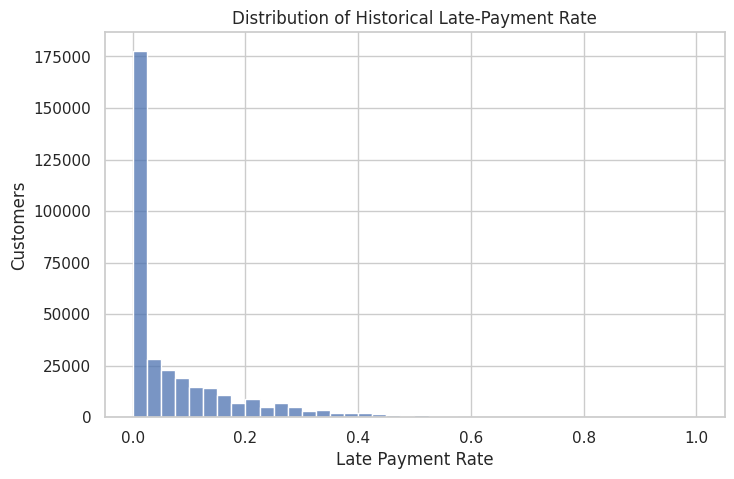

In [187]:
plt.figure(figsize=(8, 5))

sns.histplot(
    installment_features["late_payment_rate"].dropna(),
    bins=40
)

plt.title("Distribution of Historical Late-Payment Rate")
plt.xlabel("Late Payment Rate")
plt.ylabel("Customers")

plt.show()

In [188]:
application.merge(
    installment_features,
    on="SK_ID_CURR",
    how="left"
)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,payment_delay_sum,payment_delay_count,payment_delay_max,late_payment_count,payment_ratio_sum,payment_ratio_count,payment_ratio_min,average_payment_delay,late_payment_rate,average_payment_ratio
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,-388.0,19.0,-12.0,0.0,19.000000,19.0,1.000000,-20.421053,0.000000,1.000000
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,-179.0,25.0,-1.0,0.0,25.000000,25.0,1.000000,-7.160000,0.000000,1.000000
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,-23.0,3.0,-3.0,0.0,3.000000,3.0,1.000000,-7.666667,0.000000,1.000000
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,-310.0,16.0,-1.0,0.0,16.000000,16.0,1.000000,-19.375000,0.000000,1.000000
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,-240.0,66.0,12.0,16.0,63.000000,66.0,0.000050,-3.636364,0.242424,0.954545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,-254.0,7.0,-8.0,0.0,7.000000,7.0,1.000000,-36.285714,0.000000,1.000000
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,-17.0,6.0,3.0,1.0,6.000000,6.0,1.000000,-2.833333,0.166667,1.000000
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,-203.0,14.0,9.0,1.0,13.000000,14.0,0.006864,-14.500000,0.071429,0.928571
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,-361.0,19.0,-8.0,0.0,19.000000,19.0,1.000000,-19.000000,0.000000,1.000000


In [189]:
print(
    "Rows:",
    len(installment_features)
)

print(
    "Unique customers:",
    installment_features["SK_ID_CURR"].nunique()
)

Rows: 339587
Unique customers: 339587


In [190]:
#free memory
del installment_chunks
import gc
gc.collect()

1100

In [191]:
pos_sample = pd.read_csv(
    f"{DATA_PATH}/POS_CASH_balance.csv",
    nrows=10
)

pos_sample

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0
5,2207092,342166,-32,12.0,12.0,Active,0,0
6,1110516,204376,-38,48.0,43.0,Active,0,0
7,1387235,153211,-35,36.0,36.0,Active,0,0
8,1220500,112740,-31,12.0,12.0,Active,0,0
9,2371489,274851,-32,24.0,16.0,Active,0,0


In [192]:
pos_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SK_ID_PREV             10 non-null     int64  
 1   SK_ID_CURR             10 non-null     int64  
 2   MONTHS_BALANCE         10 non-null     int64  
 3   CNT_INSTALMENT         10 non-null     float64
 4   CNT_INSTALMENT_FUTURE  10 non-null     float64
 5   NAME_CONTRACT_STATUS   10 non-null     object 
 6   SK_DPD                 10 non-null     int64  
 7   SK_DPD_DEF             10 non-null     int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 772.0+ bytes


In [193]:
pos_sample.columns.tolist()

['SK_ID_PREV',
 'SK_ID_CURR',
 'MONTHS_BALANCE',
 'CNT_INSTALMENT',
 'CNT_INSTALMENT_FUTURE',
 'NAME_CONTRACT_STATUS',
 'SK_DPD',
 'SK_DPD_DEF']

In [194]:
pos_chunks = []

for chunk in pd.read_csv(
    f"{DATA_PATH}/POS_CASH_balance.csv",
    chunksize=100_000
):

    chunk["dpd_flag"] = (
        chunk["SK_DPD"] > 0
    ).astype("int8")

    chunk_agg = (
        chunk
        .groupby("SK_ID_CURR")
        .agg(

            pos_record_count=(
                "SK_ID_PREV",
                "count"
            ),

            pos_loan_count=(
                "SK_ID_PREV",
                "nunique"
            ),

            pos_dpd_sum=(
                "SK_DPD",
                "sum"
            ),

            pos_dpd_count=(
                "SK_DPD",
                "count"
            ),

            pos_dpd_max=(
                "SK_DPD",
                "max"
            ),

            pos_delinquent_month_count=(
                "dpd_flag",
                "sum"
            ),

            pos_future_installments_sum=(
                "CNT_INSTALMENT_FUTURE",
                "sum"
            ),

            pos_future_installments_count=(
                "CNT_INSTALMENT_FUTURE",
                "count"
            ),

            pos_installments_sum=(
                "CNT_INSTALMENT",
                "sum"
            ),

            pos_installments_count=(
                "CNT_INSTALMENT",
                "count"
            )
        )
        .reset_index()
    )

    pos_chunks.append(chunk_agg)

In [195]:
pos_features = pd.concat(
    pos_chunks,
    ignore_index=True
)

In [196]:
pos_features = (
    pos_features
    .groupby("SK_ID_CURR")
    .agg(

        pos_record_count=(
            "pos_record_count",
            "sum"
        ),

        pos_loan_count=(
            "pos_loan_count",
            "sum"
        ),

        pos_dpd_sum=(
            "pos_dpd_sum",
            "sum"
        ),

        pos_dpd_count=(
            "pos_dpd_count",
            "sum"
        ),

        pos_dpd_max=(
            "pos_dpd_max",
            "max"
        ),

        pos_delinquent_month_count=(
            "pos_delinquent_month_count",
            "sum"
        ),

        pos_future_installments_sum=(
            "pos_future_installments_sum",
            "sum"
        ),

        pos_future_installments_count=(
            "pos_future_installments_count",
            "sum"
        ),

        pos_installments_sum=(
            "pos_installments_sum",
            "sum"
        ),

        pos_installments_count=(
            "pos_installments_count",
            "sum"
        )
    )
    .reset_index()
)

In [197]:
pos_features["pos_dpd_mean"] = (
    pos_features["pos_dpd_sum"]
    /
    pos_features["pos_dpd_count"]
)

In [198]:
pos_features["pos_future_installments_mean"] = (
    pos_features["pos_future_installments_sum"]
    /
    pos_features["pos_future_installments_count"]
)

In [199]:
pos_features["pos_installments_mean"] = (
    pos_features["pos_installments_sum"]
    /
    pos_features["pos_installments_count"]
)

In [200]:
pos_features["pos_delinquency_rate"] = (
    pos_features["pos_delinquent_month_count"]
    /
    pos_features["pos_record_count"]
)

In [201]:
pos_features.head()

,SK_ID_CURR,pos_record_count,pos_loan_count,pos_dpd_sum,pos_dpd_count,pos_dpd_max,pos_delinquent_month_count,pos_future_installments_sum,pos_future_installments_count,pos_installments_sum,pos_installments_count,pos_dpd_mean,pos_future_installments_mean,pos_installments_mean,pos_delinquency_rate
0,100001,9,9,7,9,7,1,13.0,9,36.0,9,0.777778,1.444444,4.000000,0.111111
1,100002,19,15,0,19,0,0,285.0,19,456.0,19,0.000000,15.000000,24.000000,0.000000
2,100003,28,24,0,28,0,0,162.0,28,283.0,28,0.000000,5.785714,10.107143,0.000000
3,100004,4,4,0,4,0,0,9.0,4,15.0,4,0.000000,2.250000,3.750000,0.000000
4,100005,11,11,0,11,0,0,72.0,10,117.0,10,0.000000,7.200000,11.700000,0.000000


In [202]:
pos_features.describe()

,SK_ID_CURR,pos_record_count,pos_loan_count,pos_dpd_sum,pos_dpd_count,pos_dpd_max,pos_delinquent_month_count,pos_future_installments_sum,pos_future_installments_count,pos_installments_sum,pos_installments_count,pos_dpd_mean,pos_future_installments_mean,pos_installments_mean,pos_delinquency_rate
count,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337224.000000,337224.000000,337252.000000
mean,278163.132678,29.655445,25.537835,344.208618,29.655445,15.294106,0.875390,310.092005,29.578093,505.480080,29.578140,4.296271,9.176876,14.654990,0.021046
std,102877.889290,24.531971,20.178610,5648.480084,24.531971,151.343806,4.816039,382.481670,24.527536,591.571659,24.527667,59.717229,6.501034,7.969848,0.078553
min,100001.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,189046.750000,12.000000,11.000000,0.000000,12.000000,0.000000,0.000000,72.000000,12.000000,127.000000,12.000000,0.000000,5.000000,9.625000,0.000000
50%,278241.500000,22.000000,20.000000,0.000000,22.000000,0.000000,0.000000,164.000000,22.000000,288.000000,22.000000,0.000000,6.989411,12.000000,0.000000
75%,367320.250000,39.000000,34.000000,0.000000,39.000000,0.000000,0.000000,396.000000,39.000000,666.000000,39.000000,0.000000,11.666667,18.600000,0.000000
max,456255.000000,295.000000,226.000000,267452.000000,295.000000,4231.000000,169.000000,5539.000000,295.000000,7812.000000,295.000000,2622.078431,60.000000,72.000000,1.000000


In [203]:
print("Rows:", len(pos_features))

print(
    "Unique customers:",
    pos_features["SK_ID_CURR"].nunique()
)

Rows: 337252
Unique customers: 337252


In [204]:
pos_features = pos_features.drop(
    columns=[
        "pos_dpd_sum",
        "pos_dpd_count",
        "pos_future_installments_sum",
        "pos_future_installments_count",
        "pos_installments_sum",
        "pos_installments_count"
    ]
)

In [205]:
pos_features.head()

,SK_ID_CURR,pos_record_count,pos_loan_count,pos_dpd_max,pos_delinquent_month_count,pos_dpd_mean,pos_future_installments_mean,pos_installments_mean,pos_delinquency_rate
0,100001,9,9,7,1,0.777778,1.444444,4.000000,0.111111
1,100002,19,15,0,0,0.000000,15.000000,24.000000,0.000000
2,100003,28,24,0,0,0.000000,5.785714,10.107143,0.000000
3,100004,4,4,0,0,0.000000,2.250000,3.750000,0.000000
4,100005,11,11,0,0,0.000000,7.200000,11.700000,0.000000


In [206]:
del pos_chunks
import gc
gc.collect()

5152

In [207]:
credit_card_sample = pd.read_csv(
    f"{DATA_PATH}/credit_card_balance.csv",
    nrows=10
)

credit_card_sample

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.500,0.0,877.500,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.000,0.0,0.000,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.000,0.0,0.000,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.000,0.0,0.000,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.000,0.0,11547.000,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0
5,2646502,380010,-7,82903.815,270000,0.0,0.000,0.0,0.000,4449.105,...,82773.315,82773.315,0.0,0,0.0,0.0,2.0,Active,7,0
6,1079071,171320,-6,353451.645,585000,67500.0,67500.000,0.0,0.000,14684.175,...,351881.145,351881.145,1.0,1,0.0,0.0,6.0,Active,0,0
7,2095912,118650,-7,47962.125,45000,45000.0,45000.000,0.0,0.000,0.000,...,47962.125,47962.125,1.0,1,0.0,0.0,51.0,Active,0,0
8,2181852,367360,-4,291543.075,292500,90000.0,289339.425,0.0,199339.425,130.500,...,286831.575,286831.575,3.0,8,0.0,5.0,3.0,Active,0,0
9,1235299,203885,-5,201261.195,225000,76500.0,111026.700,0.0,34526.700,6338.340,...,197224.695,197224.695,3.0,9,0.0,6.0,38.0,Active,0,0


In [208]:
credit_card_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SK_ID_PREV                  10 non-null     int64  
 1   SK_ID_CURR                  10 non-null     int64  
 2   MONTHS_BALANCE              10 non-null     int64  
 3   AMT_BALANCE                 10 non-null     float64
 4   AMT_CREDIT_LIMIT_ACTUAL     10 non-null     int64  
 5   AMT_DRAWINGS_ATM_CURRENT    10 non-null     float64
 6   AMT_DRAWINGS_CURRENT        10 non-null     float64
 7   AMT_DRAWINGS_OTHER_CURRENT  10 non-null     float64
 8   AMT_DRAWINGS_POS_CURRENT    10 non-null     float64
 9   AMT_INST_MIN_REGULARITY     10 non-null     float64
 10  AMT_PAYMENT_CURRENT         10 non-null     float64
 11  AMT_PAYMENT_TOTAL_CURRENT   10 non-null     float64
 12  AMT_RECEIVABLE_PRINCIPAL    10 non-null     float64
 13  AMT_RECIVABLE               10 non-nul

In [209]:
credit_card_sample.columns.tolist()

['SK_ID_PREV',
 'SK_ID_CURR',
 'MONTHS_BALANCE',
 'AMT_BALANCE',
 'AMT_CREDIT_LIMIT_ACTUAL',
 'AMT_DRAWINGS_ATM_CURRENT',
 'AMT_DRAWINGS_CURRENT',
 'AMT_DRAWINGS_OTHER_CURRENT',
 'AMT_DRAWINGS_POS_CURRENT',
 'AMT_INST_MIN_REGULARITY',
 'AMT_PAYMENT_CURRENT',
 'AMT_PAYMENT_TOTAL_CURRENT',
 'AMT_RECEIVABLE_PRINCIPAL',
 'AMT_RECIVABLE',
 'AMT_TOTAL_RECEIVABLE',
 'CNT_DRAWINGS_ATM_CURRENT',
 'CNT_DRAWINGS_CURRENT',
 'CNT_DRAWINGS_OTHER_CURRENT',
 'CNT_DRAWINGS_POS_CURRENT',
 'CNT_INSTALMENT_MATURE_CUM',
 'NAME_CONTRACT_STATUS',
 'SK_DPD',
 'SK_DPD_DEF']

In [210]:
credit_card_chunks = []

for chunk in pd.read_csv(
    f"{DATA_PATH}/credit_card_balance.csv",
    chunksize=100_000
):

    chunk["credit_utilization"] = (
        chunk["AMT_BALANCE"]
        /
        chunk["AMT_CREDIT_LIMIT_ACTUAL"]
    )

    chunk["credit_utilization"] = (
        chunk["credit_utilization"]
        .replace([np.inf, -np.inf], np.nan)
    )

    chunk["dpd_flag"] = (
        chunk["SK_DPD"] > 0
    ).astype("int8")

    chunk_agg = (
        chunk
        .groupby("SK_ID_CURR")
        .agg(

            credit_card_record_count=(
                "SK_ID_PREV",
                "count"
            ),

            credit_card_loan_count=(
                "SK_ID_PREV",
                "nunique"
            ),

            credit_balance_sum=(
                "AMT_BALANCE",
                "sum"
            ),

            credit_balance_count=(
                "AMT_BALANCE",
                "count"
            ),

            credit_limit_sum=(
                "AMT_CREDIT_LIMIT_ACTUAL",
                "sum"
            ),

            credit_limit_count=(
                "AMT_CREDIT_LIMIT_ACTUAL",
                "count"
            ),

            credit_utilization_sum=(
                "credit_utilization",
                "sum"
            ),

            credit_utilization_count=(
                "credit_utilization",
                "count"
            ),

            credit_utilization_max=(
                "credit_utilization",
                "max"
            ),

            credit_dpd_sum=(
                "SK_DPD",
                "sum"
            ),

            credit_dpd_count=(
                "SK_DPD",
                "count"
            ),

            credit_dpd_max=(
                "SK_DPD",
                "max"
            ),

            credit_delinquent_month_count=(
                "dpd_flag",
                "sum"
            )
        )
        .reset_index()
    )

    credit_card_chunks.append(chunk_agg)

In [211]:
credit_card_features = pd.concat(
    credit_card_chunks,
    ignore_index=True
)

In [212]:
credit_card_features = (
    credit_card_features
    .groupby("SK_ID_CURR")
    .agg(

        credit_card_record_count=(
            "credit_card_record_count",
            "sum"
        ),

        credit_card_loan_count=(
            "credit_card_loan_count",
            "sum"
        ),

        credit_balance_sum=(
            "credit_balance_sum",
            "sum"
        ),

        credit_balance_count=(
            "credit_balance_count",
            "sum"
        ),

        credit_limit_sum=(
            "credit_limit_sum",
            "sum"
        ),

        credit_limit_count=(
            "credit_limit_count",
            "sum"
        ),

        credit_utilization_sum=(
            "credit_utilization_sum",
            "sum"
        ),

        credit_utilization_count=(
            "credit_utilization_count",
            "sum"
        ),

        credit_utilization_max=(
            "credit_utilization_max",
            "max"
        ),

        credit_dpd_sum=(
            "credit_dpd_sum",
            "sum"
        ),

        credit_dpd_count=(
            "credit_dpd_count",
            "sum"
        ),

        credit_dpd_max=(
            "credit_dpd_max",
            "max"
        ),

        credit_delinquent_month_count=(
            "credit_delinquent_month_count",
            "sum"
        )
    )
    .reset_index()
)

In [213]:
credit_card_features["credit_balance_mean"] = (
    credit_card_features["credit_balance_sum"]
    /
    credit_card_features["credit_balance_count"]
)

In [214]:
credit_card_features["credit_limit_mean"] = (
    credit_card_features["credit_limit_sum"]
    /
    credit_card_features["credit_limit_count"]
)

In [215]:
credit_card_features["credit_utilization_mean"] = (
    credit_card_features["credit_utilization_sum"]
    /
    credit_card_features["credit_utilization_count"]
)

In [216]:
credit_card_features["credit_dpd_mean"] = (
    credit_card_features["credit_dpd_sum"]
    /
    credit_card_features["credit_dpd_count"]
)

In [217]:
credit_card_features["credit_delinquency_rate"] = (
    credit_card_features["credit_delinquent_month_count"]
    /
    credit_card_features["credit_card_record_count"]
)

In [218]:
credit_card_features.head()

,SK_ID_CURR,credit_card_record_count,credit_card_loan_count,credit_balance_sum,credit_balance_count,credit_limit_sum,credit_limit_count,credit_utilization_sum,credit_utilization_count,credit_utilization_max,credit_dpd_sum,credit_dpd_count,credit_dpd_max,credit_delinquent_month_count,credit_balance_mean,credit_limit_mean,credit_utilization_mean,credit_dpd_mean,credit_delinquency_rate
0,100006,6,4,0.000,6,1620000,6,0.000000,6,0.00000,0,6,0,0,0.000000,270000.000000,0.000000,0.000000,0.000000
1,100011,74,35,4031676.225,74,12150000,74,22.398201,74,1.05000,0,74,0,0,54482.111149,164189.189189,0.302678,0.000000,0.000000
2,100013,96,33,1743352.245,96,12645000,96,11.068903,96,1.02489,1,96,1,1,18159.919219,131718.750000,0.115301,0.010417,0.010417
3,100021,17,15,0.000,17,11475000,17,0.000000,17,0.00000,0,17,0,0,0.000000,675000.000000,0.000000,0.000000,0.000000
4,100023,8,8,0.000,8,1080000,8,0.000000,8,0.00000,0,8,0,0,0.000000,135000.000000,0.000000,0.000000,0.000000


In [219]:
credit_card_features.describe()

,SK_ID_CURR,credit_card_record_count,credit_card_loan_count,credit_balance_sum,credit_balance_count,credit_limit_sum,credit_limit_count,credit_utilization_sum,credit_utilization_count,credit_utilization_max,credit_dpd_sum,credit_dpd_count,credit_dpd_max,credit_delinquent_month_count,credit_balance_mean,credit_limit_mean,credit_utilization_mean,credit_dpd_mean,credit_delinquency_rate
count,103558.000000,103558.000000,103558.000000,1.035580e+05,103558.000000,1.035580e+05,103558.000000,103558.000000,103558.000000,102445.000000,103558.000000,103558.000000,103558.000000,103558.000000,103558.000000,1.035580e+05,102445.000000,103558.000000,103558.000000
mean,278381.457956,37.083683,19.173333,2.161984e+06,37.083683,5.703765e+06,37.083683,11.166741,29.804448,0.622298,344.272572,37.083683,16.401871,1.480861,69973.192455,2.073207e+05,0.320573,4.107206,0.020027
std,102779.519683,33.483627,11.504490,3.269300e+06,33.483627,5.230569e+06,33.483627,16.777013,28.327632,0.482908,3846.103587,33.483627,141.966150,6.122852,107537.810551,1.902293e+05,0.324382,44.341025,0.076482
min,100006.000000,1.000000,1.000000,-1.260000e+05,1.000000,0.000000e+00,1.000000,-2.800000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,-2930.232558,0.000000e+00,-0.084848,0.000000,0.000000
25%,189536.250000,10.000000,9.000000,0.000000e+00,10.000000,1.404000e+06,10.000000,0.000000,9.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,8.250000e+04,0.000000,0.000000,0.000000
50%,278649.000000,22.000000,17.000000,7.013641e+05,22.000000,3.825000e+06,22.000000,4.485765,19.000000,0.939516,0.000000,22.000000,0.000000,0.000000,24997.602995,1.490000e+05,0.241313,0.000000,0.000000
75%,367690.000000,75.000000,32.000000,2.979703e+06,75.000000,9.112500e+06,75.000000,14.512522,37.000000,1.043610,0.000000,75.000000,0.000000,0.000000,96997.746023,2.675000e+05,0.583274,0.000000,0.000000
max,456250.000000,192.000000,73.000000,2.998048e+07,192.000000,3.323250e+07,192.000000,190.352282,173.000000,11.777510,150483.000000,192.000000,3260.000000,94.000000,928686.323571,1.350000e+06,2.138790,1635.684783,1.000000


In [220]:
print(
    "Rows:",
    len(credit_card_features)
)

print(
    "Unique customers:",
    credit_card_features["SK_ID_CURR"].nunique()
)

Rows: 103558
Unique customers: 103558


In [221]:
credit_card_features = credit_card_features.drop(
    columns=[
        "credit_balance_sum",
        "credit_balance_count",
        "credit_limit_sum",
        "credit_limit_count",
        "credit_utilization_sum",
        "credit_utilization_count",
        "credit_dpd_sum",
        "credit_dpd_count"
    ]
)

In [222]:
credit_card_features.head()

,SK_ID_CURR,credit_card_record_count,credit_card_loan_count,credit_utilization_max,credit_dpd_max,credit_delinquent_month_count,credit_balance_mean,credit_limit_mean,credit_utilization_mean,credit_dpd_mean,credit_delinquency_rate
0,100006,6,4,0.00000,0,0,0.000000,270000.000000,0.000000,0.000000,0.000000
1,100011,74,35,1.05000,0,0,54482.111149,164189.189189,0.302678,0.000000,0.000000
2,100013,96,33,1.02489,1,1,18159.919219,131718.750000,0.115301,0.010417,0.010417
3,100021,17,15,0.00000,0,0,0.000000,675000.000000,0.000000,0.000000,0.000000
4,100023,8,8,0.00000,0,0,0.000000,135000.000000,0.000000,0.000000,0.000000


In [223]:
del credit_card_chunks
import gc
gc.collect()

0

# Build the Final Modeling Dataset

In [224]:
datasets = {
    "application": application,
    "bureau": bureau_features,
    "bureau_balance": bureau_balance_features,
    "previous": previous_features,
    "installments": installment_features,
    "pos": pos_features,
    "credit_card": credit_card_features
}

for name, df in datasets.items():
    print(
        f"{name:20} "
        f"rows={len(df):,}  "
        f"unique_customers={df['SK_ID_CURR'].nunique():,}"
    )

application          rows=307,511  unique_customers=307,511
bureau               rows=305,811  unique_customers=305,811
bureau_balance       rows=134,542  unique_customers=134,542
previous             rows=338,857  unique_customers=338,857
installments         rows=339,587  unique_customers=339,587
pos                  rows=337,252  unique_customers=337,252
credit_card          rows=103,558  unique_customers=103,558


In [225]:
model_df = application.copy()

In [226]:
model_df = model_df.merge(
    bureau_features,
    on="SK_ID_CURR",
    how="left"
)

In [227]:
print(model_df.shape)
print(model_df["SK_ID_CURR"].nunique())

(307511, 134)
307511


In [228]:
model_df["SK_ID_CURR"].duplicated().sum()

np.int64(0)

In [229]:
model_df = model_df.merge(
    bureau_balance_features,
    on="SK_ID_CURR",
    how="left"
)

In [230]:
print(model_df.shape)
print(
    "Duplicate customers:",
    model_df["SK_ID_CURR"].duplicated().sum()
)

(307511, 139)
Duplicate customers: 0


In [231]:
model_df = model_df.merge(
    previous_features,
    on="SK_ID_CURR",
    how="left"
)

In [232]:
print(model_df.shape)
print(
    "Duplicate customers:",
    model_df["SK_ID_CURR"].duplicated().sum()
)

(307511, 147)
Duplicate customers: 0


In [233]:
model_df = model_df.merge(
    pos_features,
    on="SK_ID_CURR",
    how="left"
)

In [234]:
print(model_df.shape)
print(
    "Duplicate customers:",
    model_df["SK_ID_CURR"].duplicated().sum()
)

(307511, 155)
Duplicate customers: 0


In [235]:
model_df = model_df.merge(
    credit_card_features,
    on="SK_ID_CURR",
    how="left"
)

In [236]:
print(model_df.shape)
print(
    "Duplicate customers:",
    model_df["SK_ID_CURR"].duplicated().sum()
)

(307511, 165)
Duplicate customers: 0


In [237]:
model_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,credit_card_record_count,credit_card_loan_count,credit_utilization_max,credit_dpd_max,credit_delinquent_month_count,credit_balance_mean,credit_limit_mean,credit_utilization_mean,credit_dpd_mean,credit_delinquency_rate
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,6.0,4.0,0.0,0.0,0.0,0.0,270000.0,0.0,0.0,0.0
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [238]:
print("Rows:", model_df.shape[0])
print("Columns:", model_df.shape[1])
print("Unique customers:", model_df["SK_ID_CURR"].nunique())

Rows: 307511
Columns: 165
Unique customers: 307511


In [239]:
model_df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [240]:
model_df.dtypes.value_counts()

float64     105
int64        42
object       16
category      1
category      1
Name: count, dtype: int64

In [241]:
model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 165 entries, SK_ID_CURR to credit_delinquency_rate
dtypes: category(2), float64(105), int64(42), object(16)
memory usage: 383.0+ MB


In [242]:
final_missing = (
    model_df.isnull()
    .mean()
    .sort_values(ascending=False)
    * 100
)

final_missing.head(30)

credit_utilization_max            72.021814
credit_utilization_mean           72.021814
credit_card_loan_count            71.739222
credit_card_record_count          71.739222
credit_delinquent_month_count     71.739222
credit_limit_mean                 71.739222
credit_balance_mean               71.739222
credit_dpd_max                    71.739222
credit_delinquency_rate           71.739222
credit_dpd_mean                   71.739222
bureau_total_closed_months        70.007252
bureau_delinquency_ratio          70.007252
bureau_total_months               70.007252
bureau_total_delinquent_months    70.007252
bureau_account_count_y            70.007252
COMMONAREA_AVG                    69.872297
COMMONAREA_MEDI                   69.872297
COMMONAREA_MODE                   69.872297
NONLIVINGAPARTMENTS_MODE          69.432963
NONLIVINGAPARTMENTS_AVG           69.432963
NONLIVINGAPARTMENTS_MEDI          69.432963
FONDKAPREMONT_MODE                68.386172
LIVINGAPARTMENTS_AVG            

In [245]:
#Check whether merging changed the target distribution
original_target_rate = application["TARGET"].mean()

final_target_rate = model_df["TARGET"].mean()

print(
    "Original default rate:",
    original_target_rate
)

print(
    "Final default rate:",
    final_target_rate
)

Original default rate: 0.08072881945686496
Final default rate: 0.08072881945686496


In [247]:
print(
    "Previous application coverage:",
    model_df["previous_application_count"].notna().mean() * 100
)

Previous application coverage: 94.64929709831517


In [257]:
[col for col in model_df.columns if "install" in col.lower()]

['pos_future_installments_mean', 'pos_installments_mean']

In [258]:
installment_features.columns.tolist()

['SK_ID_CURR',
 'installment_count',
 'payment_delay_sum',
 'payment_delay_count',
 'payment_delay_max',
 'late_payment_count',
 'payment_ratio_sum',
 'payment_ratio_count',
 'payment_ratio_min']

In [259]:
print("installment_count in model_df:",
      "installment_count" in model_df.columns)

print("installment_count in installment_features:",
      "installment_count" in installment_features.columns)

installment_count in model_df: False
installment_count in installment_features: True


In [260]:
model_df = model_df.merge(
    installment_features,
    on="SK_ID_CURR",
    how="left"
)

In [261]:
print("installment_count" in model_df.columns)

True


In [262]:
print(
    "Installment history coverage:",
    model_df["installment_count"].notna().mean() * 100
)

Installment history coverage: 94.83985938714387


In [250]:
print(
    "POS/CASH history coverage:",
    model_df["pos_record_count"].notna().mean() * 100
)

POS/CASH history coverage: 94.12476301660753


In [251]:
print(
    "Credit card history coverage:",
    model_df["credit_card_record_count"].notna().mean() * 100
)

Credit card history coverage: 28.260777663238063


In [263]:
historical_checks = {
    "bureau_account_count": "bureau",
    "bureau_total_months": "bureau_balance",
    "previous_application_count": "previous",
    "installment_count": "installments",
    "pos_record_count": "pos",
    "credit_card_record_count": "credit_card"
}

for column, name in historical_checks.items():
    print(
        f"{name:20} | "
        f"{column:35} | "
        f"{column in model_df.columns}"
    )

bureau               | bureau_account_count                | False
bureau_balance       | bureau_total_months                 | True
previous             | previous_application_count          | True
installments         | installment_count                   | True
pos                  | pos_record_count                    | True
credit_card          | credit_card_record_count            | True


In [264]:
print("bureau_account_count" in bureau_features.columns)
print(bureau_features.columns.tolist())

True
['SK_ID_CURR', 'bureau_account_count', 'bureau_credit_mean', 'bureau_credit_max', 'bureau_debt_mean', 'bureau_overdue_max', 'bureau_days_credit_mean']


In [265]:
model_df = model_df.merge(
    bureau_features,
    on="SK_ID_CURR",
    how="left"
)

In [266]:
print("bureau_account_count" in model_df.columns)
print(model_df.shape)
print(model_df["SK_ID_CURR"].duplicated().sum())

True
(307511, 179)
0


In [267]:
historical_checks = {
    "bureau_account_count": "bureau",
    "bureau_total_months": "bureau_balance",
    "previous_application_count": "previous",
    "installment_count": "installments",
    "pos_record_count": "pos",
    "credit_card_record_count": "credit_card"
}

for column, name in historical_checks.items():
    print(
        f"{name:20} | "
        f"{column:35} | "
        f"{column in model_df.columns}"
    )

bureau               | bureau_account_count                | True
bureau_balance       | bureau_total_months                 | True
previous             | previous_application_count          | True
installments         | installment_count                   | True
pos                  | pos_record_count                    | True
credit_card          | credit_card_record_count            | True


In [268]:
duplicate_columns = (
    model_df.columns[
        model_df.columns.duplicated()
    ]
)

duplicate_columns

Index([], dtype='object')

In [269]:
duplicate_customers = (
    model_df["SK_ID_CURR"].duplicated().sum()
)

print(
    "Duplicate customer/application rows:",
    duplicate_customers
)

Duplicate customer/application rows: 0


# Save the intermediate modeling dataset

In [270]:
model_df.to_parquet(
    "/kaggle/working/home_credit_model_features.parquet",
    index=False
)

In [271]:
import os

os.path.getsize(
    "/kaggle/working/home_credit_model_features.parquet"
) / (1024 ** 2)

51.430548667907715

# #Leakage Prevention


In [272]:
X = model_df.drop(columns=["TARGET"])
y = model_df["TARGET"]

In [273]:
bureau_time_sample = pd.read_csv(
    f"{DATA_PATH}/bureau.csv",
    usecols=[
        "SK_ID_CURR",
        "DAYS_CREDIT"
    ],
    nrows=100000
)

bureau_time_sample["DAYS_CREDIT"].describe()

count    100000.000000
mean      -1130.975350
std         791.668833
min       -2922.000000
25%       -1643.000000
50%        -973.000000
75%        -468.000000
max           0.000000
Name: DAYS_CREDIT, dtype: float64

In [274]:
(
    bureau_time_sample["DAYS_CREDIT"] > 0
).sum()

np.int64(0)

In [275]:
(
    bureau_time_sample["DAYS_CREDIT"] >= 0
).mean() * 100

np.float64(0.001)

In [276]:
previous_time_sample = pd.read_csv(
    f"{DATA_PATH}/previous_application.csv",
    usecols=[
        "SK_ID_CURR",
        "DAYS_DECISION"
    ],
    nrows=100000
)

previous_time_sample["DAYS_DECISION"].describe()

count    100000.000000
mean       -902.911130
std         787.791457
min       -2922.000000
25%       -1346.000000
50%        -602.000000
75%        -292.000000
max          -2.000000
Name: DAYS_DECISION, dtype: float64

In [277]:
(previous_time_sample["DAYS_DECISION"] > 0).sum()

np.int64(0)

In [278]:
median_income = model_df["AMT_INCOME_TOTAL"].median()

In [280]:
[
    col for col in model_df.columns
    if "TARGET" in col.upper()
]

['TARGET']

In [281]:
[
    col for col in model_df.columns
    if "ID" in col.upper()
]

['SK_ID_CURR', 'DAYS_ID_PUBLISH']

In [282]:
print(
    "Original target rows:",
    len(application)
)

print(
    "Final target rows:",
    len(model_df)
)

print(
    "Original default rate:",
    application["TARGET"].mean()
)

print(
    "Final default rate:",
    model_df["TARGET"].mean()
)

Original target rows: 307511
Final target rows: 307511
Original default rate: 0.08072881945686496
Final default rate: 0.08072881945686496


In [283]:
print(
    "Duplicate SK_ID_CURR:",
    model_df["SK_ID_CURR"].duplicated().sum()
)

Duplicate SK_ID_CURR: 0


# #Feature Engineering + Data Cleaning 

In [284]:
df = model_df.copy()

print(df.shape)

(307511, 179)


In [285]:
(df["DAYS_EMPLOYED"] == 365243).sum()

np.int64(55374)

In [286]:
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

In [287]:
df["EMPLOYMENT_YEARS"] = (
    -df["DAYS_EMPLOYED"] / 365.25
)

In [288]:
df["EMPLOYMENT_YEARS"].describe()

count    252137.000000
mean          6.527500
std           6.402081
min          -0.000000
25%           2.099932
50%           4.511978
75%           8.692676
max          49.040383
Name: EMPLOYMENT_YEARS, dtype: float64

In [289]:
df["AGE_YEARS"] = (
    -df["DAYS_BIRTH"] / 365.25
)

In [290]:
df["AGE_YEARS"].describe()

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: AGE_YEARS, dtype: float64

In [291]:
df["CREDIT_TO_INCOME"] = (
    df["AMT_CREDIT"] /
    df["AMT_INCOME_TOTAL"]
)

In [292]:
df["ANNUITY_TO_INCOME"] = (
    df["AMT_ANNUITY"] /
    df["AMT_INCOME_TOTAL"]
)

In [293]:
df["CREDIT_TO_ANNUITY"] = (
    df["AMT_CREDIT"] /
    df["AMT_ANNUITY"]
)

In [294]:
#Prevent infinite values

ratio_columns = [
    "CREDIT_TO_INCOME",
    "ANNUITY_TO_INCOME",
    "CREDIT_TO_ANNUITY"
]

for col in ratio_columns:
    print(
        col,
        "infinite:",
        np.isinf(df[col]).sum()
    )

CREDIT_TO_INCOME infinite: 0
ANNUITY_TO_INCOME infinite: 0
CREDIT_TO_ANNUITY infinite: 0


In [295]:
df[ratio_columns] = (
    df[ratio_columns]
    .replace([np.inf, -np.inf], np.nan)
)

In [296]:
df["INCOME_PER_FAMILY_MEMBER"] = (
    df["AMT_INCOME_TOTAL"] /
    df["CNT_FAM_MEMBERS"]
)

In [297]:
df["INCOME_PER_FAMILY_MEMBER"] = (
    df["INCOME_PER_FAMILY_MEMBER"]
    .replace([np.inf, -np.inf], np.nan)
)

In [298]:
previous_cols = [
    col for col in df.columns
    if col.startswith("previous_")
]

previous_cols

['previous_application_count',
 'previous_approved_count',
 'previous_refused_count',
 'previous_credit_max',
 'previous_credit_mean',
 'previous_application_amount_mean',
 'previous_approval_rate',
 'previous_refusal_rate']

In [299]:
installment_cols = [
    col for col in df.columns
    if "payment" in col.lower()
    or "installment" in col.lower()
]

installment_cols

['pos_future_installments_mean',
 'pos_installments_mean',
 'installment_count',
 'payment_delay_sum',
 'payment_delay_count',
 'payment_delay_max',
 'late_payment_count',
 'payment_ratio_sum',
 'payment_ratio_count',
 'payment_ratio_min']

In [300]:
[
    col for col in df.columns
    if col.startswith("credit_")
]

['credit_card_record_count',
 'credit_card_loan_count',
 'credit_utilization_max',
 'credit_dpd_max',
 'credit_delinquent_month_count',
 'credit_balance_mean',
 'credit_limit_mean',
 'credit_utilization_mean',
 'credit_dpd_mean',
 'credit_delinquency_rate']

In [301]:
df["credit_utilization_mean"].describe()

count    86036.000000
mean         0.326981
std          0.325396
min         -0.084848
25%          0.000000
50%          0.253387
75%          0.592000
max          2.138790
Name: credit_utilization_mean, dtype: float64

In [302]:
[
    col for col in df.columns
    if "bureau" in col.lower()
]

['AMT_REQ_CREDIT_BUREAU_HOUR',
 'AMT_REQ_CREDIT_BUREAU_DAY',
 'AMT_REQ_CREDIT_BUREAU_WEEK',
 'AMT_REQ_CREDIT_BUREAU_MON',
 'AMT_REQ_CREDIT_BUREAU_QRT',
 'AMT_REQ_CREDIT_BUREAU_YEAR',
 'bureau_account_count_x',
 'bureau_credit_mean_x',
 'bureau_credit_max_x',
 'bureau_debt_mean_x',
 'bureau_overdue_max_x',
 'bureau_days_credit_mean_x',
 'bureau_total_months',
 'bureau_total_delinquent_months',
 'bureau_total_closed_months',
 'bureau_account_count_y',
 'bureau_delinquency_ratio',
 'bureau_account_count',
 'bureau_credit_mean_y',
 'bureau_credit_max_y',
 'bureau_debt_mean_y',
 'bureau_overdue_max_y',
 'bureau_days_credit_mean_y']

In [303]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 307511
Columns: 182


In [304]:
##Examine missing values now

missing = (
    df.isnull()
    .mean()
    .sort_values(ascending=False)
    * 100
)

missing.head(30)

credit_utilization_mean           72.021814
credit_utilization_max            72.021814
credit_balance_mean               71.739222
credit_delinquent_month_count     71.739222
credit_limit_mean                 71.739222
credit_dpd_max                    71.739222
credit_card_record_count          71.739222
credit_card_loan_count            71.739222
credit_dpd_mean                   71.739222
credit_delinquency_rate           71.739222
bureau_total_delinquent_months    70.007252
bureau_total_closed_months        70.007252
bureau_account_count_y            70.007252
bureau_delinquency_ratio          70.007252
bureau_total_months               70.007252
COMMONAREA_MODE                   69.872297
COMMONAREA_AVG                    69.872297
COMMONAREA_MEDI                   69.872297
NONLIVINGAPARTMENTS_AVG           69.432963
NONLIVINGAPARTMENTS_MODE          69.432963
NONLIVINGAPARTMENTS_MEDI          69.432963
FONDKAPREMONT_MODE                68.386172
LIVINGAPARTMENTS_MEDI           

In [305]:
missing[missing > 50]

credit_utilization_mean           72.021814
credit_utilization_max            72.021814
credit_balance_mean               71.739222
credit_delinquent_month_count     71.739222
credit_limit_mean                 71.739222
credit_dpd_max                    71.739222
credit_card_record_count          71.739222
credit_card_loan_count            71.739222
credit_dpd_mean                   71.739222
credit_delinquency_rate           71.739222
bureau_total_delinquent_months    70.007252
bureau_total_closed_months        70.007252
bureau_account_count_y            70.007252
bureau_delinquency_ratio          70.007252
bureau_total_months               70.007252
COMMONAREA_MODE                   69.872297
COMMONAREA_AVG                    69.872297
COMMONAREA_MEDI                   69.872297
NONLIVINGAPARTMENTS_AVG           69.432963
NONLIVINGAPARTMENTS_MODE          69.432963
NONLIVINGAPARTMENTS_MEDI          69.432963
FONDKAPREMONT_MODE                68.386172
LIVINGAPARTMENTS_MEDI           

In [306]:
##Remove extremely sparse columns

very_sparse = missing[missing > 90]

print(very_sparse)

Series([], dtype: float64)


In [307]:
sparse_columns = very_sparse.index.tolist()

df = df.drop(
    columns=sparse_columns
)

print("Removed:", len(sparse_columns))
print("New shape:", df.shape)

Removed: 0
New shape: (307511, 182)


In [308]:
print(
    "Duplicate full rows:",
    df.duplicated().sum()
)

Duplicate full rows: 0


In [309]:
print(
    "Duplicate customers:",
    df["SK_ID_CURR"].duplicated().sum()
)

Duplicate customers: 0


In [310]:
##Check numerical outliers

important_numeric = [
    "AGE_YEARS",
    "EMPLOYMENT_YEARS",
    "CREDIT_TO_INCOME",
    "ANNUITY_TO_INCOME",
    "CREDIT_TO_ANNUITY",
    "INCOME_PER_FAMILY_MEMBER"
]

df[important_numeric].describe(
    percentiles=[
        0.01,
        0.05,
        0.50,
        0.95,
        0.99
    ]
)

,AGE_YEARS,EMPLOYMENT_YEARS,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TO_ANNUITY,INCOME_PER_FAMILY_MEMBER
count,307511.000000,252137.000000,307511.000000,307499.000000,307499.000000,3.075090e+05
mean,43.906900,6.527500,3.957570,0.180930,21.612322,9.310588e+04
std,11.947950,6.402081,2.689728,0.094574,7.823823,1.013734e+05
min,20.503765,-0.000000,0.004808,0.000224,8.036674,2.812500e+03
1%,22.622861,0.303901,0.595365,0.039474,8.709985,1.800000e+04
5%,25.754962,0.563997,1.000000,0.062633,9.523526,2.700000e+04
50%,43.121150,4.511978,3.265067,0.162833,20.000000,7.500000e+04
95%,63.529090,19.961670,9.156739,0.354667,34.542314,2.250000e+05
99%,66.855578,31.042519,13.027280,0.483458,37.794118,3.375000e+05
max,69.073238,49.040383,84.736842,1.875965,45.305079,3.900000e+07


In [311]:
df["AGE_YEARS"].describe()

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: AGE_YEARS, dtype: float64

In [312]:
(
    (df["AGE_YEARS"] < 18) |
    (df["AGE_YEARS"] > 100)
).sum()

np.int64(0)

In [313]:
df["CNT_FAM_MEMBERS"].describe()

count    307509.000000
mean          2.152665
std           0.910682
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          20.000000
Name: CNT_FAM_MEMBERS, dtype: float64

In [314]:
df["CNT_CHILDREN"].describe()

count    307511.000000
mean          0.417052
std           0.722121
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [315]:
df["CNT_CHILDREN"].describe()

count    307511.000000
mean          0.417052
std           0.722121
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [316]:
#separate target and ID

X = df.drop(
    columns=[
        "TARGET",
        "SK_ID_CURR"
    ]
)

y = df["TARGET"]

In [317]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 180)
y shape: (307511,)


In [318]:
#Check the feature types

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 162
Categorical features: 18


In [319]:
print("Categorical columns:")
print(categorical_features)

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'AGE_GROUP', 'EMPLOYMENT_GROUP']


# ##Train/Validation Split + Preprocessing Pipeline  

In [320]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [321]:
print("Overall:")
print(y.value_counts(normalize=True))

print("\nTraining:")
print(y_train.value_counts(normalize=True))

print("\nValidation:")
print(y_valid.value_counts(normalize=True))

Overall:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Training:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Validation:
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [322]:
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (246008, 180)
X_valid: (61503, 180)
y_train: (246008,)
y_valid: (61503,)


# Now identify numerical and categorical features

In [323]:
numeric_features = X_train.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 162
Categorical features: 18


In [324]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [325]:
#Create the numerical pipeline:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [326]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [327]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)


                  X
                  │
          ┌───────┴────────┐
          ↓                ↓
     Numerical         Categorical
          │                │
       Median            Most frequent
       Imputer              │
          │             One-Hot Encode
     StandardScaler         │
          │                │
          └───────┬────────┘
                  ↓
          Processed features

In [328]:
y_train.value_counts(normalize=True) * 100

TARGET
0    91.927092
1     8.072908
Name: proportion, dtype: float64

In [329]:
##Calculate XGBoost class weight
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

scale_pos_weight

np.float64(11.38710976837865)

In [330]:
print(
    y_valid.value_counts(normalize=True) * 100
)

TARGET
0    91.927223
1     8.072777
Name: proportion, dtype: float64


# First test: fit only the preprocessing

In [331]:
X_train_processed = preprocessor.fit_transform(X_train)

In [332]:
X_valid_processed = preprocessor.transform(X_valid)

In [333]:
print(
    "Training processed shape:",
    X_train_processed.shape
)

print(
    "Validation processed shape:",
    X_valid_processed.shape
)

Training processed shape: (246008, 313)
Validation processed shape: (61503, 313)


In [334]:
type(X_train_processed)

numpy.ndarray

In [335]:
del X_train_processed
del X_valid_processed

import gc
gc.collect()

2098

# Train and Compare 5 Classification Models

In [340]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Number of numerical features: 162
Number of categorical features: 18


In [341]:
##Build the numerical pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [342]:
###Build the categorical pipeline
from sklearn.preprocessing import OneHotEncoder


categorical_pipeline_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [343]:
##Combine both pipelines

from sklearn.compose import ColumnTransformer

preprocessor_lr = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_lr,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_lr,
            categorical_features
        )
    ]
)

In [344]:
#testing pipeline
X_train_transformed = preprocessor_lr.fit_transform(
    X_train
)

In [345]:
#validating pipeline
X_valid_transformed = preprocessor_lr.transform(
    X_valid
)

In [346]:
print("Original X_train shape:", X_train.shape)
print("Transformed X_train shape:", X_train_transformed.shape)

print("Original X_valid shape:", X_valid.shape)
print("Transformed X_valid shape:", X_valid_transformed.shape)

Original X_train shape: (246008, 180)
Transformed X_train shape: (246008, 313)
Original X_valid shape: (61503, 180)
Transformed X_valid shape: (61503, 313)


# Logistic Regression


In [347]:
from sklearn.linear_model import LogisticRegression

logistic_classifier = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [348]:
#Combine preprocessing + model

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_lr
        ),
        (
            "classifier",
            logistic_classifier
        )
    ]
)

In [349]:
#model training

logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_C...
                                                   'NAME_INCOME_TYPE',
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE',
                                                   'AGE_GROUP',
                                                   'EMPLOYMENT_GROUP'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [350]:
logistic_prob = logistic_model.predict_proba(
    X_valid
)[:, 1]

Evaluate ROC-AUC

In [351]:
from sklearn.metrics import roc_auc_score

logistic_roc_auc = roc_auc_score(
    y_valid,
    logistic_prob
)

print(
    "Logistic Regression ROC-AUC:",
    logistic_roc_auc
)

Logistic Regression ROC-AUC: 0.7673895199824076


Evaluate PR-AUC

In [352]:
from sklearn.metrics import average_precision_score

logistic_pr_auc = average_precision_score(
    y_valid,
    logistic_prob
)

print(
    "Logistic Regression PR-AUC:",
    logistic_pr_auc
)

Logistic Regression PR-AUC: 0.25150368228756215


In [353]:
#Convert probability to prediction

threshold = 0.50

logistic_pred = (
    logistic_prob >= threshold
).astype(int)

In [354]:
from sklearn.metrics import precision_score

logistic_precision = precision_score(
    y_valid,
    logistic_pred,
    zero_division=0
)

print(
    "Precision:",
    logistic_precision
)

Precision: 0.17185023771790808


In [355]:
from sklearn.metrics import recall_score

logistic_recall = recall_score(
    y_valid,
    logistic_pred,
    zero_division=0
)

print(
    "Recall:",
    logistic_recall
)

Recall: 0.6988922457200403


In [356]:
from sklearn.metrics import f1_score

logistic_f1 = f1_score(
    y_valid,
    logistic_pred,
    zero_division=0
)

print(
    "F1:", 
    logistic_f1
)

F1: 0.2758675517748539


In [358]:
from sklearn.metrics import confusion_matrix

logistic_cm = confusion_matrix(
    y_valid,
    logistic_pred
)

print(logistic_cm)

[[39816 16722]
 [ 1495  3470]]


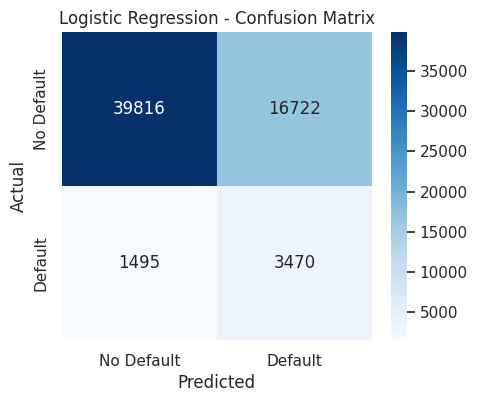

In [359]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [360]:
logistic_results = {
    "Model": "Logistic Regression",
    "ROC-AUC": logistic_roc_auc,
    "PR-AUC": logistic_pr_auc,
    "Precision": logistic_precision,
    "Recall": logistic_recall,
    "F1": logistic_f1
}

logistic_results

{'Model': 'Logistic Regression',
 'ROC-AUC': np.float64(0.7673895199824076),
 'PR-AUC': np.float64(0.25150368228756215),
 'Precision': 0.17185023771790808,
 'Recall': 0.6988922457200403,
 'F1': 0.2758675517748539}

# #Random forest 

In [361]:
##build preproceessor

#numerical
numeric_pipeline_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)
#categorial
categorical_pipeline_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)
#combine
preprocessor_rf = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_rf,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_rf,
            categorical_features
        )
    ]
)

In [362]:
#buildng random forest

from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

In [363]:
#combine preprocessing and random forest
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_rf
        ),
        (
            "classifier",
            rf_classifier
        )
    ]
)

In [365]:
##train the model 
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_CAR_AGE', 'FLAG_MOBIL',
                                                   'FLAG_E...
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE',
                                                   'AGE_GROUP',
                                                   'EMPLOYMENT_GROUP'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=250, n_jobs=-1,
                                        random_state=42))])

In [366]:
rf_prob = random_forest_model.predict_proba(
    X_valid
)[:, 1]

In [377]:
rf_roc_auc = roc_auc_score(
    y_valid,
    rf_prob
)

print(
    "Random Forest ROC-AUC:",
    rf_roc_auc
)

rf_pr_auc = average_precision_score(
    y_valid,
    rf_prob
)

print(
    "Random Forest PR-AUC:",
    rf_pr_auc
)

#Convert probabilities to classes
rf_pred = (
    rf_prob >= 0.50
).astype(int)


rf_precision = precision_score(
    y_valid,
    rf_pred,
    zero_division=0
)

print(
    "Random Forest Precision:",
    rf_precision
)

rf_recall = recall_score(
    y_valid,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_valid,
    rf_pred,
    zero_division=0
)

print(
    "Random Forest F1:",
    rf_f1
)

Random Forest ROC-AUC: 0.7531869323190807
Random Forest PR-AUC: 0.22218328082237035
Random Forest Precision: 0.3333333333333333
Random Forest F1: 0.002408187838651415


In [378]:
#confusion metric
rf_cm = confusion_matrix(
    y_valid,
    rf_pred
)

print(rf_cm)

[[56526    12]
 [ 4959     6]]


In [379]:
rf_results = {
    "Model": "Random Forest",
    "ROC-AUC": rf_roc_auc,
    "PR-AUC": rf_pr_auc,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1": rf_f1
}

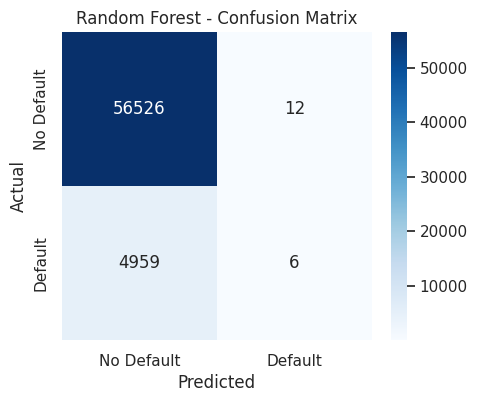

In [380]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# MODEL 3: EXTRA TREES

In [382]:
numeric_pipeline_et = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline_et = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor_et = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_et,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_et,
            categorical_features
        )
    ]
)

In [371]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_classifier = ExtraTreesClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

In [372]:
extra_trees_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_et
        ),
        (
            "classifier",
            extra_trees_classifier
        )
    ]
)

In [373]:
extra_trees_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_CAR_AGE', 'FLAG_MOBIL',
                                                   'FLAG_E...
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE',
                                                   'AGE_GROUP',
                                                   'EMPLOYMENT_GROUP'])])),
                ('classifier',
                 ExtraTreesClassifier(class_weight='balanced', n_estimators=250,
                                      n_jobs=-1, random_state=42))])

In [383]:
extra_trees_prob = (
    extra_trees_model
    .predict_proba(X_valid)[:, 1]
)

In [384]:
extra_trees_roc_auc = roc_auc_score(
    y_valid,
    extra_trees_prob
)

print(
    "Extra Trees ROC-AUC:",
    extra_trees_roc_auc
)

extra_trees_pr_auc = average_precision_score(
    y_valid,
    extra_trees_prob
)

print(
    "Extra Trees PR-AUC:",
    extra_trees_pr_auc
)

# Convert probabilities to predictions
extra_trees_pred = (
    extra_trees_prob >= 0.50
).astype(int)


extra_trees_precision = precision_score(
    y_valid,
    extra_trees_pred,
    zero_division=0
)

print(
    "Extra Trees Precision:",
    extra_trees_precision
)

extra_trees_recall = recall_score(
    y_valid,
    extra_trees_pred,
    zero_division=0
)

print(
    "Extra Trees Recall:",
    extra_trees_recall
)

extra_trees_f1 = f1_score(
    y_valid,
    extra_trees_pred,
    zero_division=0
)

print(
    "Extra Trees F1:",
    extra_trees_f1
)

Extra Trees ROC-AUC: 0.7458301605881946
Extra Trees PR-AUC: 0.22288828601556343
Extra Trees Precision: 0.7777777777777778
Extra Trees Recall: 0.0014098690835850957
Extra Trees F1: 0.0028146361077603537


In [385]:
extra_trees_cm = confusion_matrix(
    y_valid,
    extra_trees_pred
)

print(extra_trees_cm)

[[56536     2]
 [ 4958     7]]


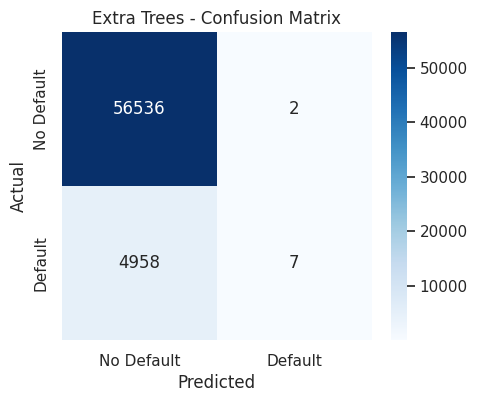

In [386]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    extra_trees_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("Extra Trees - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [387]:
extra_trees_results = {
    "Model": "Extra Trees",
    "ROC-AUC": extra_trees_roc_auc,
    "PR-AUC": extra_trees_pr_auc,
    "Precision": extra_trees_precision,
    "Recall": extra_trees_recall,
    "F1": extra_trees_f1
}

extra_trees_results

{'Model': 'Extra Trees',
 'ROC-AUC': np.float64(0.7458301605881946),
 'PR-AUC': np.float64(0.22288828601556343),
 'Precision': 0.7777777777777778,
 'Recall': 0.0014098690835850957,
 'F1': 0.0028146361077603537}

# #MODEL 4: HistGradientBoosting 

In [388]:
numeric_pipeline_hgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline_hgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor_hgb = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_hgb,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_hgb,
            categorical_features
        )
    ]
)

In [389]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_classifier = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

In [390]:
hist_gradient_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_hgb
        ),
        (
            "classifier",
            hgb_classifier
        )
    ]
)

In [391]:
hist_gradient_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_CAR_AGE', 'FLAG_MOBIL',
                                                   'FLAG_E...
                                                   'NAME_INCOME_TYPE',
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE',
                                                   'AGE_GROUP',
                                                   'EMPLOYMENT_GROUP'])])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=200,
                                                random_state=42))])

In [392]:
hgb_prob = (
    hist_gradient_model
    .predict_proba(X_valid)[:, 1]
)

In [393]:
hgb_roc_auc = roc_auc_score(
    y_valid,
    hgb_prob
)

print(
    "HistGradientBoosting ROC-AUC:",
    hgb_roc_auc
)

hgb_pr_auc = average_precision_score(
    y_valid,
    hgb_prob
)

print(
    "HistGradientBoosting PR-AUC:",
    hgb_pr_auc
)

#Create binary predictions
hgb_pred = (
    hgb_prob >= 0.50
).astype(int)

hgb_precision = precision_score(
    y_valid,
    hgb_pred,
    zero_division=0
)

print(
    "HistGradientBoosting Precision:",
    hgb_precision
)

hgb_recall = recall_score(
    y_valid,
    hgb_pred,
    zero_division=0
)

print(
    "HistGradientBoosting Recall:",
    hgb_recall
)

hgb_f1 = f1_score(
    y_valid,
    hgb_pred,
    zero_division=0
)

print(
    "HistGradientBoosting F1:",
    hgb_f1
)

HistGradientBoosting ROC-AUC: 0.7795577425721961
HistGradientBoosting PR-AUC: 0.27299240343518427
HistGradientBoosting Precision: 0.5762081784386617
HistGradientBoosting Recall: 0.03121852970795569
HistGradientBoosting F1: 0.0592281238058846


In [394]:
hgb_cm = confusion_matrix(
    y_valid,
    hgb_pred
)

print(hgb_cm)

[[56424   114]
 [ 4810   155]]


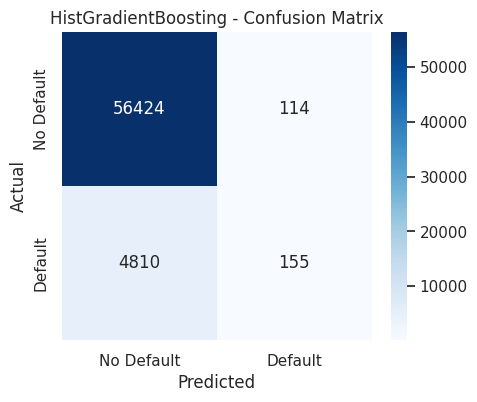

In [395]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    hgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("HistGradientBoosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [396]:
hist_gradient_results = {
    "Model": "HistGradientBoosting",
    "ROC-AUC": hgb_roc_auc,
    "PR-AUC": hgb_pr_auc,
    "Precision": hgb_precision,
    "Recall": hgb_recall,
    "F1": hgb_f1
}

hist_gradient_results

{'Model': 'HistGradientBoosting',
 'ROC-AUC': np.float64(0.7795577425721961),
 'PR-AUC': np.float64(0.27299240343518427),
 'Precision': 0.5762081784386617,
 'Recall': 0.03121852970795569,
 'F1': 0.0592281238058846}

# MODEL 5: XGBoost

In [397]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(scale_pos_weight)

11.38710976837865


In [398]:
numeric_pipeline_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_xgb,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_xgb,
            categorical_features
        )
    ]
)

In [399]:
from xgboost import XGBClassifier
xgb_classifier = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

In [400]:
#creating full pipeline
xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_xgb
        ),
        (
            "classifier",
            xgb_classifier
        )
    ]
)

In [401]:
#training model
xgb_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRATION',
                                                   'DAYS_ID_PUBLISH',
                                                   'OWN_CAR_AGE', 'FLAG_MOBIL',
                                                   'FLAG_E...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [402]:
#generate probabilities
xgb_prob = (
    xgb_model
    .predict_proba(X_valid)[:, 1]
)

In [403]:
print(xgb_prob[:10])
print("Predictions:", len(xgb_prob))
print("Validation rows:", len(y_valid))

[0.28505823 0.388081   0.8395405  0.267372   0.5020228  0.48316842
 0.14746474 0.06948671 0.7772674  0.40332034]
Predictions: 61503
Validation rows: 61503


In [404]:
xgb_roc_auc = roc_auc_score(
    y_valid,
    xgb_prob
)

print(
    "XGBoost ROC-AUC:",
    xgb_roc_auc
)

xgb_pr_auc = average_precision_score(
    y_valid,
    xgb_prob
)

print(
    "XGBoost PR-AUC:",
    xgb_pr_auc
)

#probabilities to classes
xgb_pred = (
    xgb_prob >= 0.50
).astype(int)

xgb_precision = precision_score(
    y_valid,
    xgb_pred,
    zero_division=0
)

print(
    "XGBoost Precision:",
    xgb_precision
)

xgb_recall = recall_score(
    y_valid,
    xgb_pred,
    zero_division=0
)

print(
    "XGBoost Recall:",
    xgb_recall
)

xgb_f1 = f1_score(
    y_valid,
    xgb_pred,
    zero_division=0
)

print(
    "XGBoost F1:",
    xgb_f1
)

XGBoost ROC-AUC: 0.7817586489344189
XGBoost PR-AUC: 0.27466258684040845
XGBoost Precision: 0.19252957286871394
XGBoost Recall: 0.6654582074521651
XGBoost F1: 0.2986531682183856


In [405]:
xgb_cm = confusion_matrix(
    y_valid,
    xgb_pred
)

print(xgb_cm)

[[42681 13857]
 [ 1661  3304]]


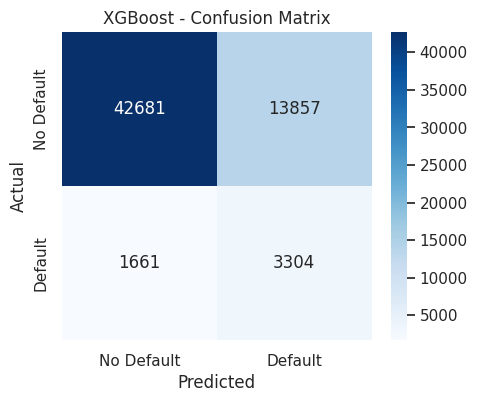

In [406]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [407]:
xgb_results = {
    "Model": "XGBoost",
    "ROC-AUC": xgb_roc_auc,
    "PR-AUC": xgb_pr_auc,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1": xgb_f1
}

xgb_results

{'Model': 'XGBoost',
 'ROC-AUC': np.float64(0.7817586489344189),
 'PR-AUC': np.float64(0.27466258684040845),
 'Precision': 0.19252957286871394,
 'Recall': 0.6654582074521651,
 'F1': 0.2986531682183856}

# comparing all the models

In [408]:
comparison_df = pd.DataFrame([
    logistic_results,
    rf_results,
    extra_trees_results,
    hist_gradient_results,
    xgb_results
])

comparison_df = comparison_df.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,XGBoost,0.781759,0.274663,0.192530,0.665458,0.298653
1,HistGradientBoosting,0.779558,0.272992,0.576208,0.031219,0.059228
2,Logistic Regression,0.767390,0.251504,0.171850,0.698892,0.275868
3,Extra Trees,0.745830,0.222888,0.777778,0.001410,0.002815
4,Random Forest,0.753187,0.222183,0.333333,0.001208,0.002408


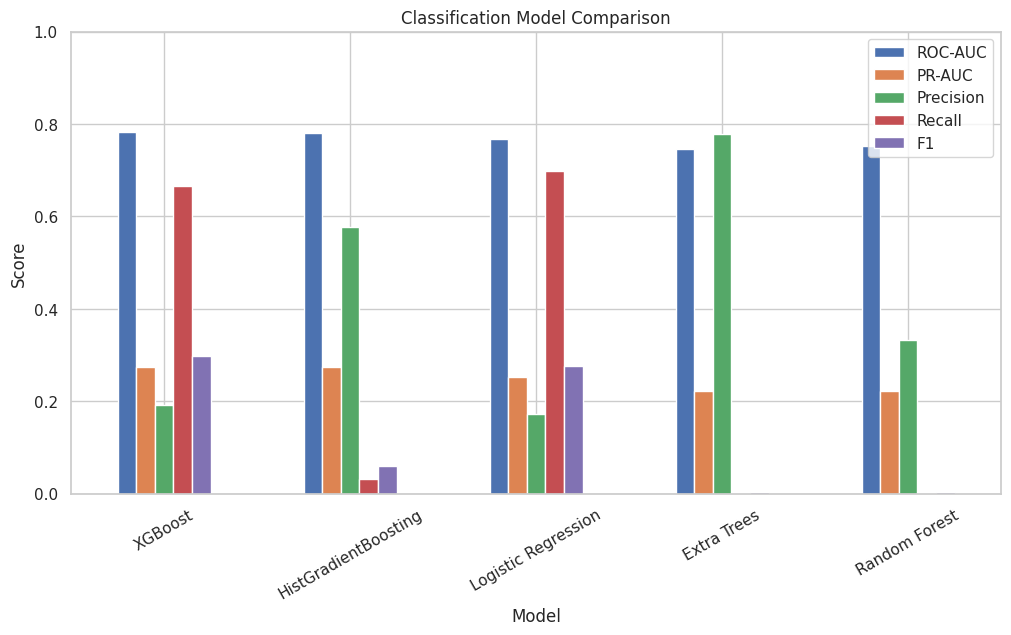

In [409]:
metrics_to_plot = [
    "ROC-AUC",
    "PR-AUC",
    "Precision",
    "Recall",
    "F1"
]

comparison_df.set_index("Model")[
    metrics_to_plot
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=30)
plt.legend()

plt.show()

In [415]:
print("Extra Trees")
print("Precision:", extra_trees_precision)
print("Recall:", extra_trees_recall)
print("F1:", extra_trees_f1)

print("\nRandom Forest")
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1:", rf_f1)



print("Extra Trees predicted defaults:",
      extra_trees_pred.sum())

print("Random Forest predicted defaults:",
      rf_pred.sum())

print("Actual defaults:",
      y_valid.sum())

Extra Trees
Precision: 0.7777777777777778
Recall: 0.0014098690835850957
F1: 0.0028146361077603537

Random Forest
Precision: 0.3333333333333333
Recall: 0.0012084592145015106
F1: 0.002408187838651415
Extra Trees predicted defaults: 9
Random Forest predicted defaults: 18
Actual defaults: 4965


In [410]:
model_probabilities = {
    "Logistic Regression": logistic_prob,
    "Random Forest": rf_prob,
    "Extra Trees": extra_trees_prob,
    "HistGradientBoosting": hgb_prob,
    "XGBoost": xgb_prob
}

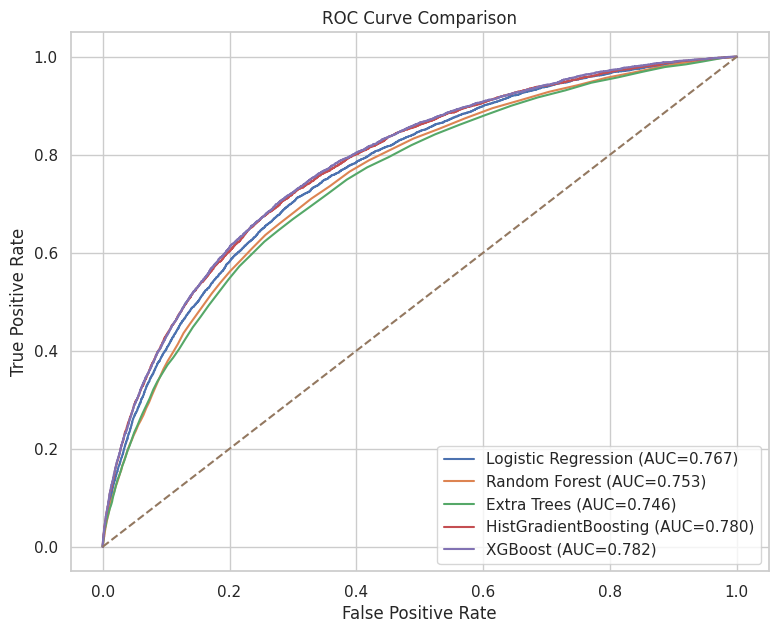

In [411]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_valid,
        probabilities
    )

    auc = roc_auc_score(
        y_valid,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

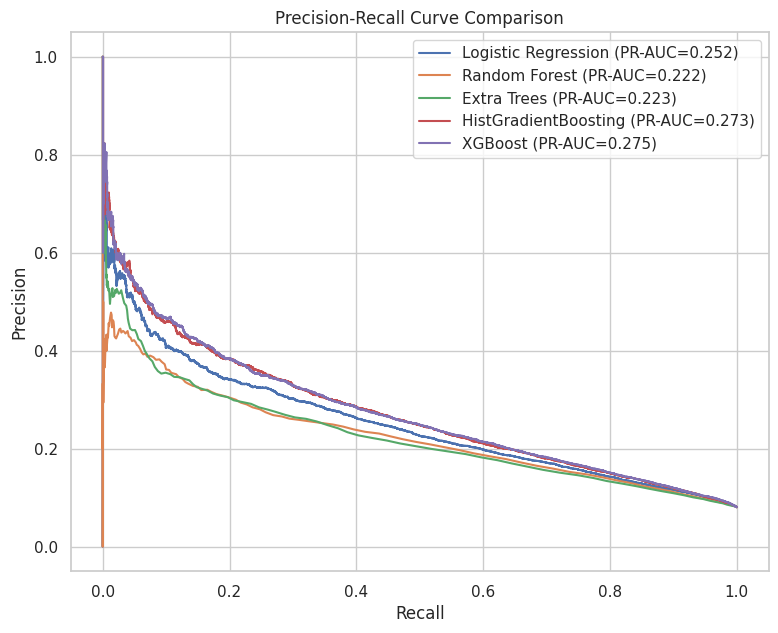

In [412]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(9, 7))

for model_name, probabilities in model_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_valid,
        probabilities
    )

    pr_auc = average_precision_score(
        y_valid,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC={pr_auc:.3f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()

plt.show()

In [413]:
best_model_name = comparison_df.loc[
    comparison_df["PR-AUC"].idxmax(),
    "Model"
]

print(
    "Best model based on PR-AUC:",
    best_model_name
)

best_roc_model = comparison_df.loc[
    comparison_df["ROC-AUC"].idxmax(),
    "Model"
]

print(
    "Best model based on ROC-AUC:",
    best_roc_model
)

Best model based on PR-AUC: XGBoost
Best model based on ROC-AUC: XGBoost


In [414]:
comparison_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

# ### ##  Hyperparameter Tuning  

In [416]:
##Create a tuning subset

print("Training rows:", len(X_train))

from sklearn.model_selection import train_test_split

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(100_000, len(X_train)),
    random_state=42,
    stratify=y_train
)

Training rows: 246008


In [417]:
print("Tuning rows:", len(X_tune))
print(y_tune.value_counts(normalize=True))

Tuning rows: 100000
TARGET
0    0.91927
1    0.08073
Name: proportion, dtype: float64


Build a fresh XGBoost pipeline for tuning

In [418]:
numeric_pipeline_tune = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline_tune = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


preprocessor_tune = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline_tune,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline_tune,
            categorical_features
        )
    ]
)

--> Build the baseline tuning pipeline

In [419]:
xgb_tuning_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_tune
        ),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                n_jobs=-1,
                random_state=42,
                scale_pos_weight=scale_pos_weight
            )
        )
    ]
)

# Define the hyperparameter search space

In [420]:
from scipy.stats import randint, uniform

param_distributions = {
    "classifier__n_estimators": randint(
        200, 500
    ),

    "classifier__max_depth": randint(
        3, 9
    ),

    "classifier__learning_rate": uniform(
        0.02, 0.08
    ),

    "classifier__subsample": uniform(
        0.7, 0.3
    ),

    "classifier__colsample_bytree": uniform(
        0.7, 0.3
    ),

    "classifier__min_child_weight": randint(
        1, 10
    ),

    "classifier__reg_alpha": uniform(
        0.0, 1.0
    ),

    "classifier__reg_lambda": uniform(
        0.5, 2.0
    )
}

# Create RandomizedSearchCV

In [421]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=1,
    refit=True
)

In [422]:
#run the search 
random_search.fit(
    X_tune,
    y_tune
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END classifier__colsample_bytree=0.8123620356542087, classifier__learning_rate=0.0960571445127933, classifier__max_depth=5, classifier__min_child_weight=8, classifier__n_estimators=388, classifier__reg_alpha=0.596850157946487, classifier__reg_lambda=1.3916655057071823, classifier__subsample=0.7299924747454009; total time=  12.8s
[CV] END classifier__colsample_bytree=0.8123620356542087, classifier__learning_rate=0.0960571445127933, classifier__max_depth=5, classifier__min_child_weight=8, classifier__n_estimators=388, classifier__reg_alpha=0.596850157946487, classifier__reg_lambda=1.3916655057071823, classifier__subsample=0.7299924747454009; total time=  12.7s
[CV] END classifier__colsample_bytree=0.8123620356542087, classifier__learning_rate=0.0960571445127933, classifier__max_depth=5, classifier__min_child_weight=8, classifier__n_estimators=388, classifier__reg_alpha=0.596850157946487, classifier__reg_lambda=1.3916655057

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['CNT_CHILDREN',
                                                                                'AMT_INCOME_TOTAL',
                                                                                'AMT_CREDIT',
                                                                                'AMT_ANNUITY',
                                                                                'AMT_GOODS_PRICE',
                                                                                'REGION_POPULATION_RELATIVE',
                                                                                'DAYS_BIRTH',
                                                                                'DAYS_EMPLOYED',
                                                                                'DAYS_REGISTRATION',
                                                                                'DAYS_ID_PUBLISH',...
                                        'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x781f61d487d0>,
                                        'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x781f61d4b620>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x781f61d29d30>},
                   random_state=42, scoring='average_precision', verbose=2)

In [423]:
print("Best parameters:")
print(random_search.best_params_)

Best parameters:
{'classifier__colsample_bytree': np.float64(0.9040922615763338), 'classifier__learning_rate': np.float64(0.056039940157563445), 'classifier__max_depth': 4, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 288, 'classifier__reg_alpha': np.float64(0.9656320330745594), 'classifier__reg_lambda': np.float64(2.1167946962329225), 'classifier__subsample': np.float64(0.7913841307520112)}


In [424]:
print(
    "Best CV PR-AUC:",
    random_search.best_score_
)

Best CV PR-AUC: 0.2551894679347111


In [425]:
best_xgb_tuned = random_search.best_estimator_  ##getting best pipeline

In [426]:
#generate tuned probabilities

tuned_xgb_prob = (
    best_xgb_tuned
    .predict_proba(X_valid)[:, 1]
)

In [427]:
tuned_xgb_roc_auc = roc_auc_score(
    y_valid,
    tuned_xgb_prob
)

tuned_xgb_pr_auc = average_precision_score(
    y_valid,
    tuned_xgb_prob
)

print(
    "Tuned XGBoost ROC-AUC:",
    tuned_xgb_roc_auc
)

print(
    "Tuned XGBoost PR-AUC:",
    tuned_xgb_pr_auc
)

Tuned XGBoost ROC-AUC: 0.7759767468462335
Tuned XGBoost PR-AUC: 0.27104787683696685


In [428]:
#compare baseline vs tuned xg...
tuning_comparison = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC"
    ],

    "Baseline XGBoost": [
        xgb_roc_auc,
        xgb_pr_auc
    ],

    "Tuned XGBoost": [
        tuned_xgb_roc_auc,
        tuned_xgb_pr_auc
    ]
})

tuning_comparison

,Metric,Baseline XGBoost,Tuned XGBoost
0,ROC-AUC,0.781759,0.775977
1,PR-AUC,0.274663,0.271048


# Now evaluate tuned XGBoost at threshold 0.50

In [429]:
tuned_xgb_pred = (
    tuned_xgb_prob >= 0.50
).astype(int)

tuned_xgb_precision = precision_score(
    y_valid,
    tuned_xgb_pred,
    zero_division=0
)

tuned_xgb_recall = recall_score(
    y_valid,
    tuned_xgb_pred,
    zero_division=0
)

tuned_xgb_f1 = f1_score(
    y_valid,
    tuned_xgb_pred,
    zero_division=0
)

print("Precision:", tuned_xgb_precision)
print("Recall:", tuned_xgb_recall)
print("F1:", tuned_xgb_f1)

Precision: 0.18395686979251757
Recall: 0.6803625377643504
F1: 0.28960905349794236


In [430]:
#confusion metrix
tuned_xgb_cm = confusion_matrix(
    y_valid,
    tuned_xgb_pred
)

print(tuned_xgb_cm)

[[41553 14985]
 [ 1587  3378]]


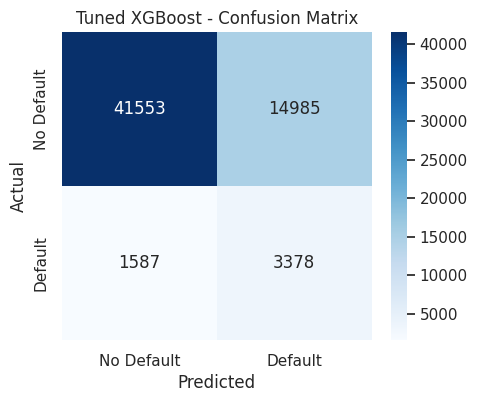

In [431]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    tuned_xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title("Tuned XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# #Threshold Optimization 

In [432]:
##Start by checking a range of thresholds

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        tuned_xgb_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_valid,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_valid,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_valid,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.085058,0.994361,0.156710
1,0.15,0.091564,0.980866,0.167492
2,0.20,0.100080,0.955488,0.181183
3,0.25,0.109978,0.923464,0.196549
4,0.30,0.121499,0.887815,0.213747
5,0.35,0.133514,0.841289,0.230455
6,0.40,0.148211,0.794965,0.249842
7,0.45,0.164845,0.741390,0.269720
8,0.50,0.183957,0.680363,0.289609
9,0.55,0.207071,0.611078,0.309324


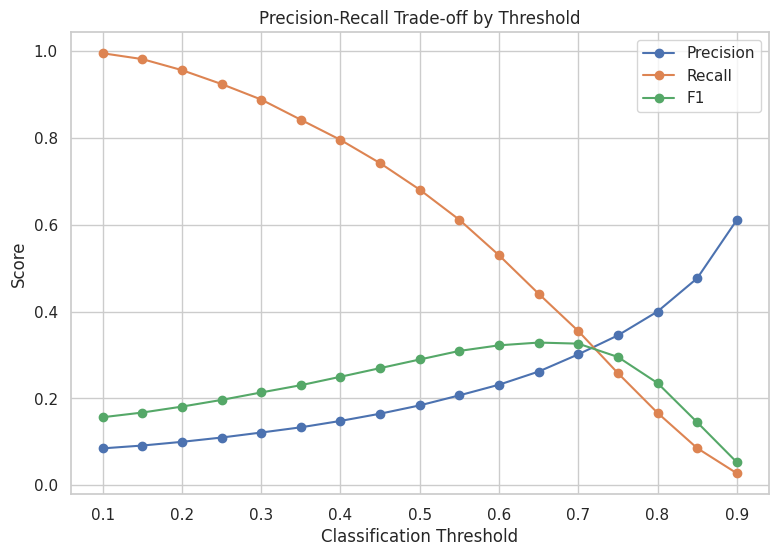

In [433]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Trade-off by Threshold")
plt.legend()

plt.show()

In [434]:
#Find the F1-optimal threshold

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_f1_threshold = best_f1_row["Threshold"]

print(
    "Best F1 threshold:",
    best_f1_threshold
)

print(
    "Best F1:",
    best_f1_row["F1"]
)

print(
    "Precision:",
    best_f1_row["Precision"]
)

print(
    "Recall:",
    best_f1_row["Recall"]
)

Best F1 threshold: 0.6500000000000001
Best F1: 0.3285306918805343
Precision: 0.26181078818323167
Recall: 0.4408862034239678


In [435]:
####A practical threshold approach


target_recall = 0.60

eligible_thresholds = threshold_df[
    threshold_df["Recall"] >= target_recall
]

eligible_thresholds

best_business_row = (
    eligible_thresholds
    .sort_values(
        "Precision",
        ascending=False
    )
    .iloc[0]
)

best_business_row

Threshold    0.550000
Precision    0.207071
Recall       0.611078
F1           0.309324
Name: 9, dtype: float64

# final threshold

In [436]:
final_threshold = best_f1_threshold

print(
    "Selected threshold:",
    final_threshold
)

Selected threshold: 0.6500000000000001


In [439]:
final_predictions = (
    tuned_xgb_prob >= final_threshold
).astype(int)

In [440]:
final_threshold = best_business_row["Threshold"]

print(
    "Selected business threshold:",
    final_threshold
)


final_precision = precision_score(
    y_valid,
    final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_valid,
    final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_valid,
    final_predictions,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_valid,
    tuned_xgb_prob
)

final_pr_auc = average_precision_score(
    y_valid,
    tuned_xgb_prob
)

print("Final Threshold:", final_threshold)
print("ROC-AUC:", final_roc_auc)
print("PR-AUC:", final_pr_auc)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1:", final_f1)

Selected business threshold: 0.5500000000000002
Final Threshold: 0.5500000000000002
ROC-AUC: 0.7759767468462335
PR-AUC: 0.27104787683696685
Precision: 0.20707070707070707
Recall: 0.6110775427995971
F1: 0.3093235459040628


In [441]:
final_cm = confusion_matrix(
    y_valid,
    final_predictions
)

print(final_cm)

[[44920 11618]
 [ 1931  3034]]


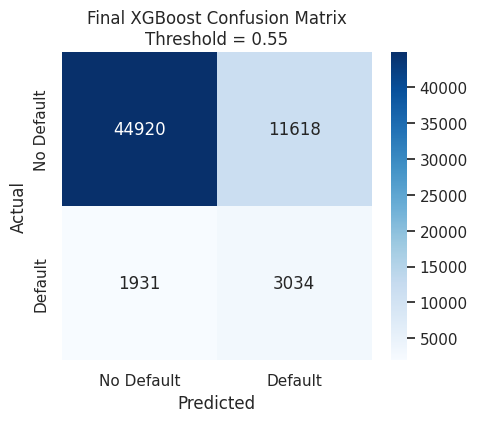

In [442]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Default",
        "Default"
    ],
    yticklabels=[
        "No Default",
        "Default"
    ]
)

plt.title(
    f"Final XGBoost Confusion Matrix\n"
    f"Threshold = {final_threshold:.2f}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [443]:
TN, FP, FN, TP = final_cm.ravel()

print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives  :", TP)

True Negatives : 44920
False Positives: 11618
False Negatives: 1931
True Positives  : 3034


In [444]:
actual_defaults = y_valid.sum()
identified_defaults = TP

print(
    "Actual defaults:",
    actual_defaults
)

print(
    "Defaults identified:",
    identified_defaults
)

print(
    "Default detection rate:",
    identified_defaults / actual_defaults
)

Actual defaults: 4965
Defaults identified: 3034
Default detection rate: 0.6110775427995971


In [445]:
#the final model summary

final_model_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1",
        "Threshold"
    ],
    "Value": [
        final_roc_auc,
        final_pr_auc,
        final_precision,
        final_recall,
        final_f1,
        final_threshold
    ]
})

final_model_summary

,Metric,Value
0,ROC-AUC,0.775977
1,PR-AUC,0.271048
2,Precision,0.207071
3,Recall,0.611078
4,F1,0.309324
5,Threshold,0.550000


In [446]:
feature_names = (
    best_xgb_tuned
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

In [447]:
print("Number of transformed features:", len(feature_names))
print(feature_names[:20])

Number of transformed features: 313
['numerical__CNT_CHILDREN' 'numerical__AMT_INCOME_TOTAL'
 'numerical__AMT_CREDIT' 'numerical__AMT_ANNUITY'
 'numerical__AMT_GOODS_PRICE' 'numerical__REGION_POPULATION_RELATIVE'
 'numerical__DAYS_BIRTH' 'numerical__DAYS_EMPLOYED'
 'numerical__DAYS_REGISTRATION' 'numerical__DAYS_ID_PUBLISH'
 'numerical__OWN_CAR_AGE' 'numerical__FLAG_MOBIL'
 'numerical__FLAG_EMP_PHONE' 'numerical__FLAG_WORK_PHONE'
 'numerical__FLAG_CONT_MOBILE' 'numerical__FLAG_PHONE'
 'numerical__FLAG_EMAIL' 'numerical__CNT_FAM_MEMBERS'
 'numerical__REGION_RATING_CLIENT'
 'numerical__REGION_RATING_CLIENT_W_CITY']


In [451]:
#Extract XGBoost feature importance
final_xgb_classifier = (
    best_xgb_tuned
    .named_steps["classifier"]
)
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_xgb_classifier.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)
feature_importance_df.head(20)

,Feature,Importance
0,numerical__EXT_SOURCE_2,0.031087
1,numerical__EXT_SOURCE_3,0.030627
2,numerical__EXT_SOURCE_1,0.014119
3,categorical__NAME_EDUCATION_TYPE_Secondary / s...,0.013741
4,categorical__NAME_EDUCATION_TYPE_Higher education,0.013675
5,categorical__CODE_GENDER_F,0.013043
6,categorical__CODE_GENDER_M,0.010196
7,numerical__FLAG_DOCUMENT_3,0.009827
8,numerical__previous_refusal_rate,0.009672
9,numerical__AGE_YEARS,0.009511


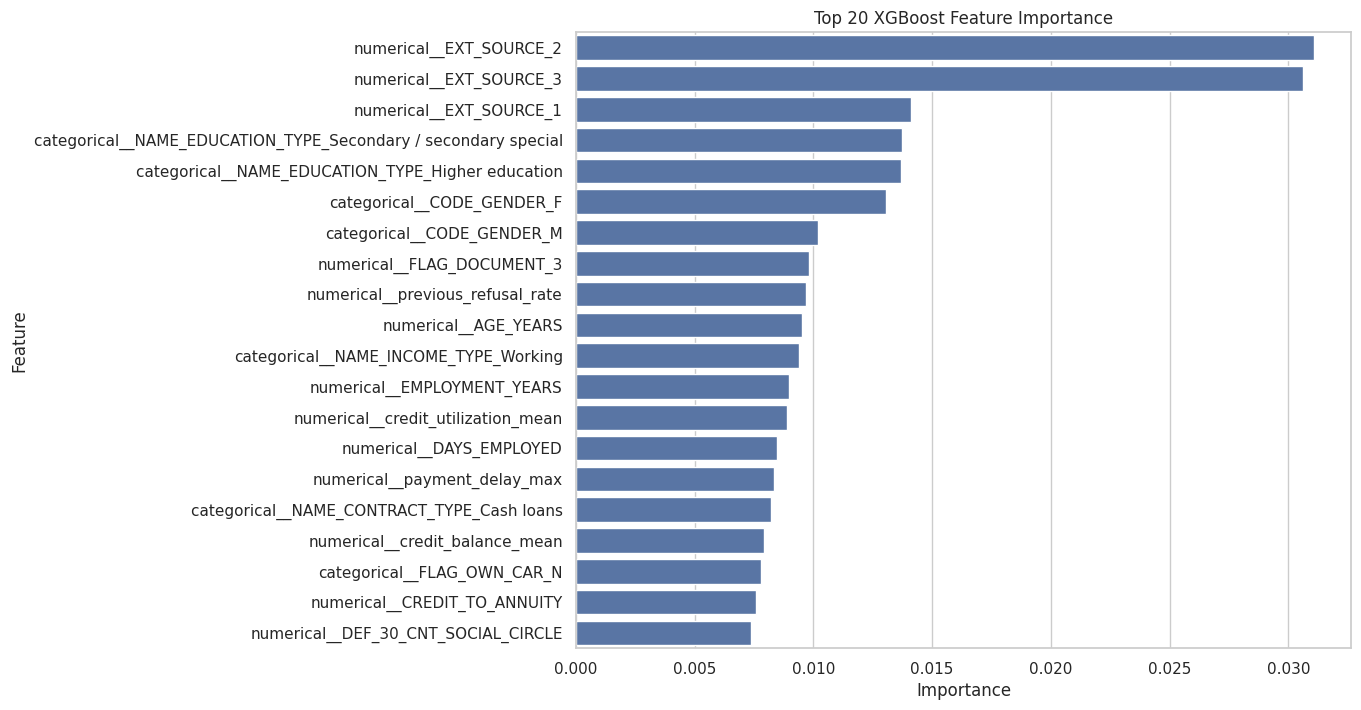

In [452]:
top_features = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 XGBoost Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

# SHAP

In [453]:
import shap

In [454]:
#transformed data

shap_sample_size = min(
    5000,
    len(X_valid)
)

X_shap = X_valid.sample(
    n=shap_sample_size,
    random_state=42
)

In [455]:
#transform shap sample
final_preprocessor = (
    best_xgb_tuned
    .named_steps["preprocessor"]
)

In [456]:
X_shap_transformed = (
    final_preprocessor
    .transform(X_shap)
)

In [457]:
print(
    "SHAP sample shape:",
    X_shap_transformed.shape
)

SHAP sample shape: (5000, 313)


# Create the SHAP explainer

In [458]:
explainer = shap.TreeExplainer(
    final_xgb_classifier
)
shap_values = explainer(
    X_shap_transformed
)

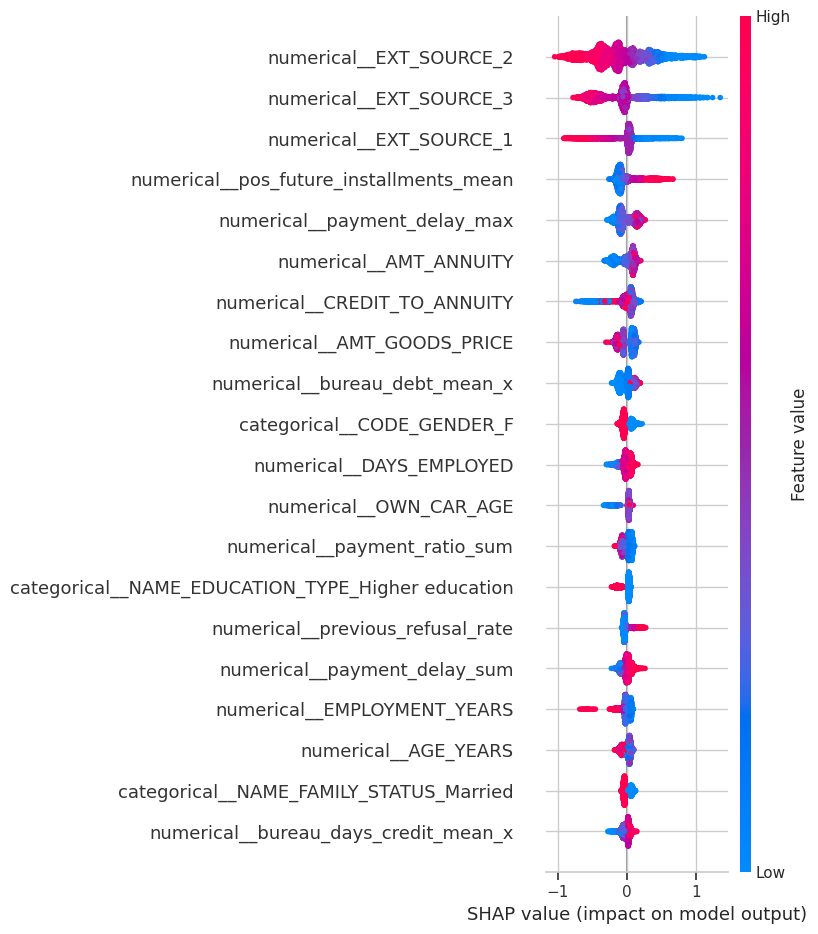

In [459]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    show=True
)

# Global feature importance using SHAP

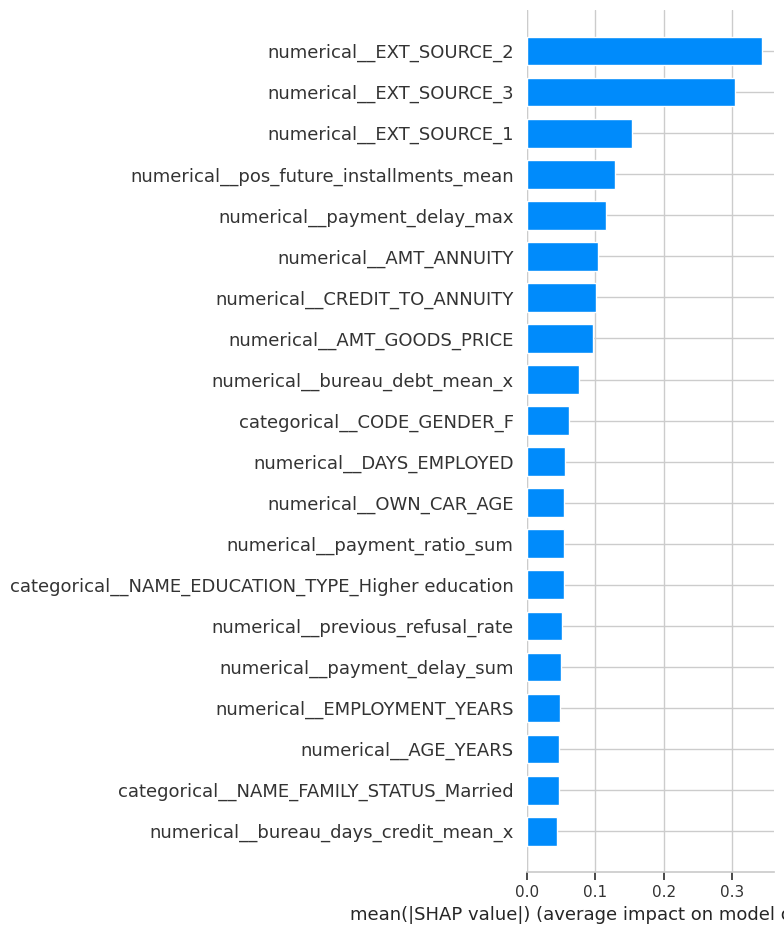

In [460]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

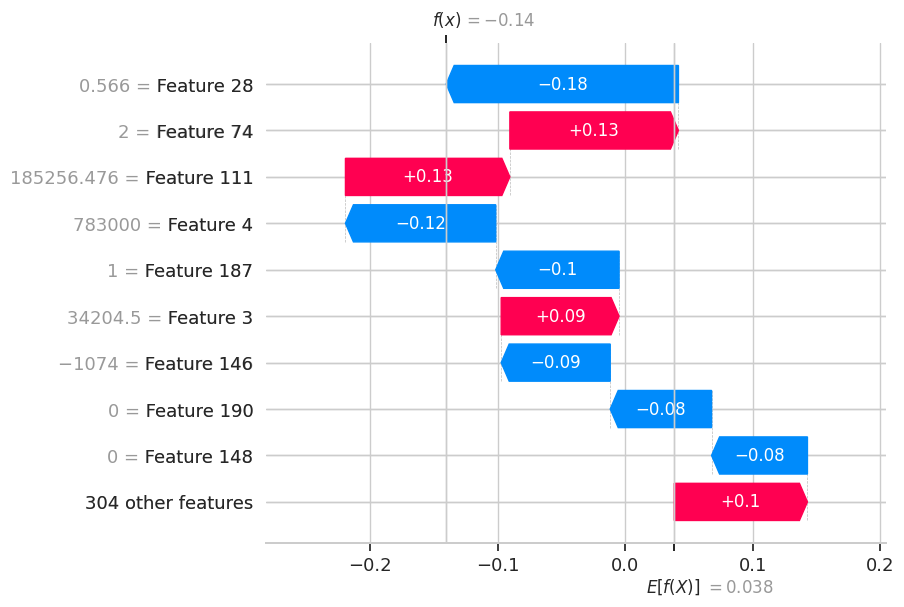

In [461]:
customer_index = 0
shap.plots.waterfall(
    shap_values[customer_index]
)

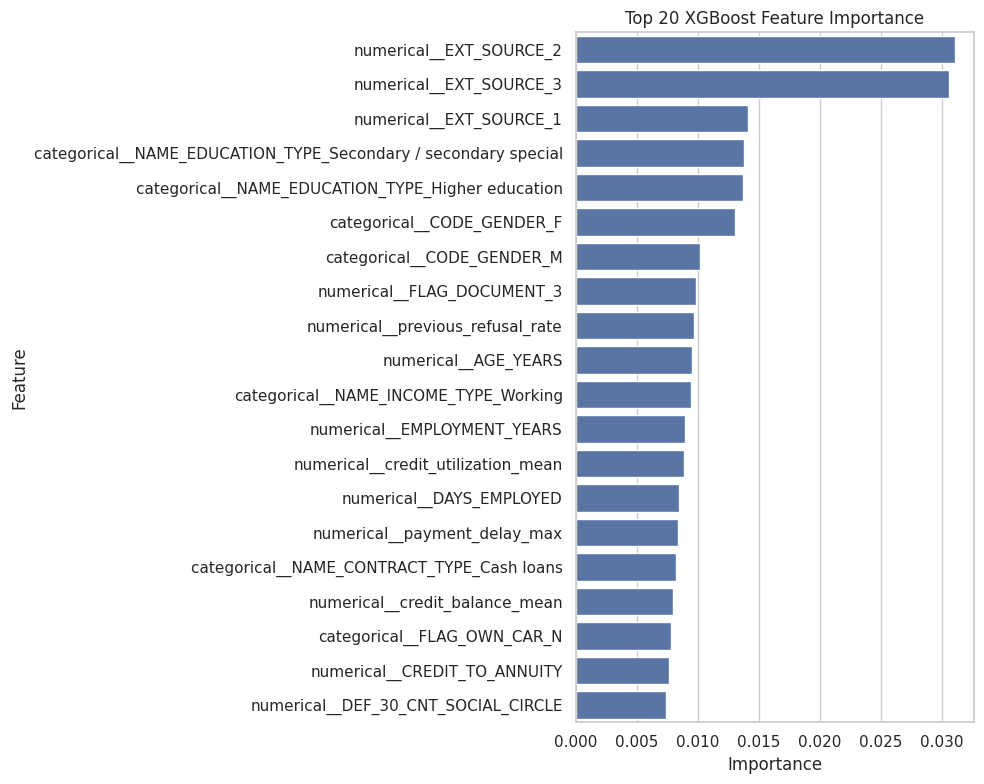

In [462]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 XGBoost Feature Importance")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

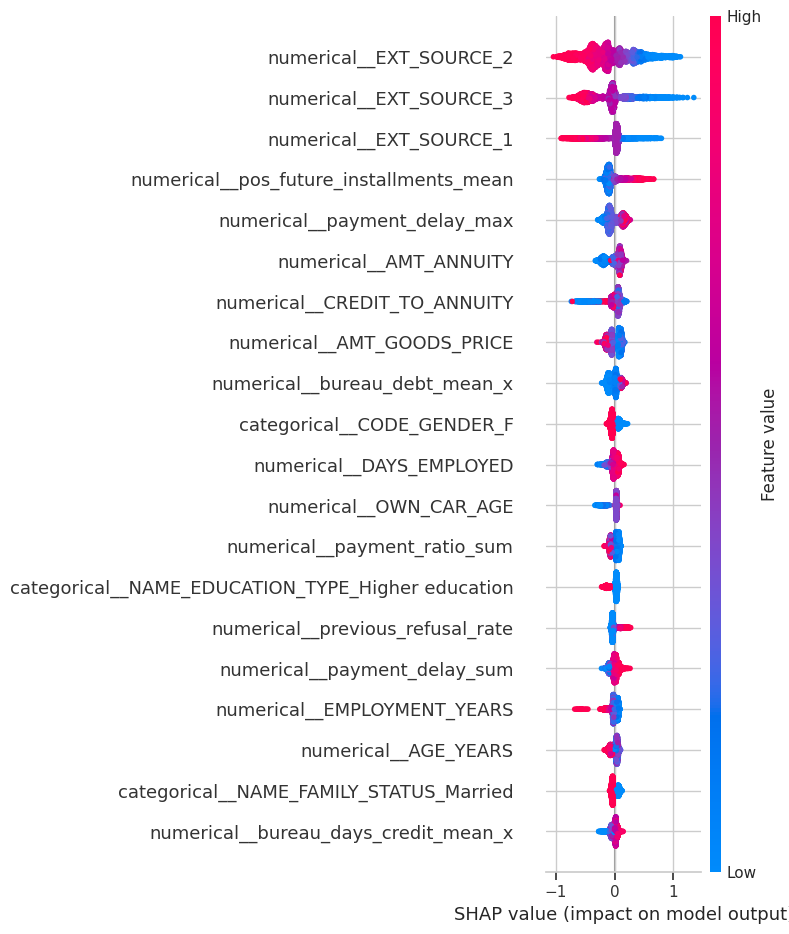

In [463]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

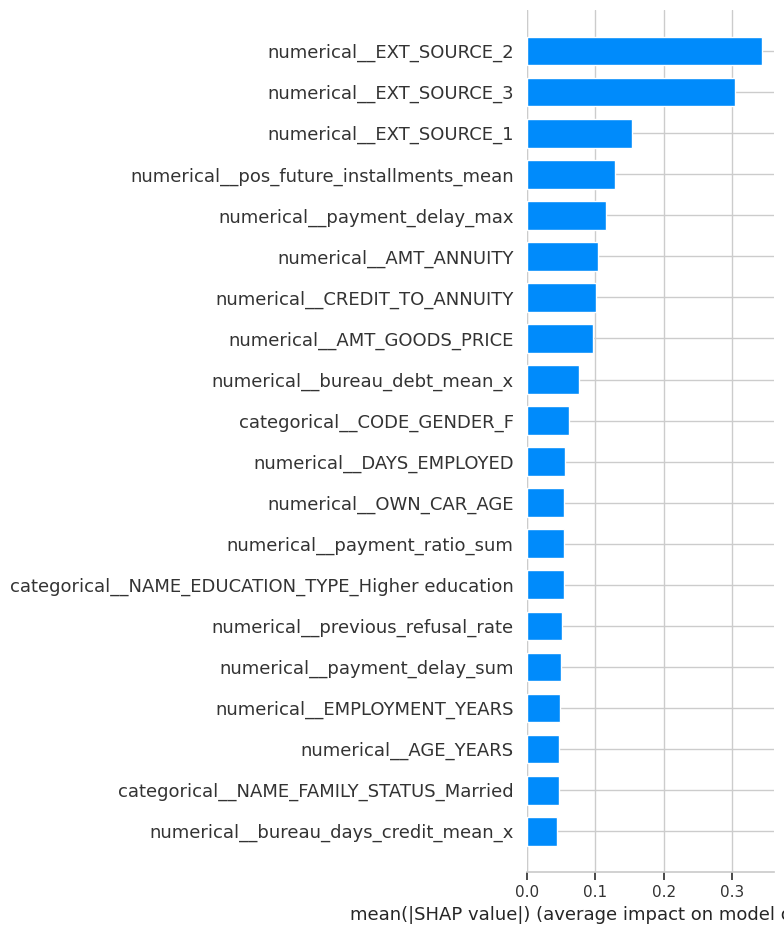

In [464]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# #final probabilities: 

In [465]:
def risk_band(probability):
    if probability < 0.20:
        return "Low Risk"
    elif probability < 0.40:
        return "Medium Risk"
    elif probability < 0.60:
        return "High Risk"
    else:
        return "Very High Risk"

In [466]:
risk_bands = pd.Series(
    tuned_xgb_prob,
    index=X_valid.index
).apply(risk_band)

In [467]:
risk_bands.value_counts()

Medium Risk       20771
High Risk         15277
Low Risk          14101
Very High Risk    11354
Name: count, dtype: int64

In [468]:

#risk table
risk_summary = pd.DataFrame({
    "Default_Probability": tuned_xgb_prob,
    "Risk_Band": risk_bands,
    "Actual_TARGET": y_valid
})


In [469]:
risk_summary.head()

,Default_Probability,Risk_Band,Actual_TARGET
256571,0.255589,Medium Risk,0
191493,0.320328,Medium Risk,0
103497,0.775803,Very High Risk,0
130646,0.304529,Medium Risk,0
211898,0.537661,High Risk,0


In [470]:
comparison_df.round(4)
comparison_df.round(4).to_csv(
    "/kaggle/working/final_model_comparison.csv",
    index=False
)
final_model_summary.round(4)
final_predictions

array([0, 0, 1, ..., 0, 1, 1])

final metrics

In [471]:
final_metrics = {
    "ROC-AUC": final_roc_auc,
    "PR-AUC": final_pr_auc,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1,
    "Threshold": final_threshold
}

final_metrics

{'ROC-AUC': np.float64(0.7759767468462335),
 'PR-AUC': np.float64(0.27104787683696685),
 'Precision': 0.20707070707070707,
 'Recall': 0.6110775427995971,
 'F1': 0.3093235459040628,
 'Threshold': np.float64(0.5500000000000002)}

In [472]:
final_metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Value"]
)

final_metrics_df

,Metric,Value
0,ROC-AUC,0.775977
1,PR-AUC,0.271048
2,Precision,0.207071
3,Recall,0.611078
4,F1,0.309324
5,Threshold,0.550000


In [473]:
final_metrics_df.to_csv(
    "/kaggle/working/final_model_metrics.csv",
    index=False
)

In [474]:
feature_importance_df.head(20)

,Feature,Importance
0,numerical__EXT_SOURCE_2,0.031087
1,numerical__EXT_SOURCE_3,0.030627
2,numerical__EXT_SOURCE_1,0.014119
3,categorical__NAME_EDUCATION_TYPE_Secondary / s...,0.013741
4,categorical__NAME_EDUCATION_TYPE_Higher education,0.013675
5,categorical__CODE_GENDER_F,0.013043
6,categorical__CODE_GENDER_M,0.010196
7,numerical__FLAG_DOCUMENT_3,0.009827
8,numerical__previous_refusal_rate,0.009672
9,numerical__AGE_YEARS,0.009511


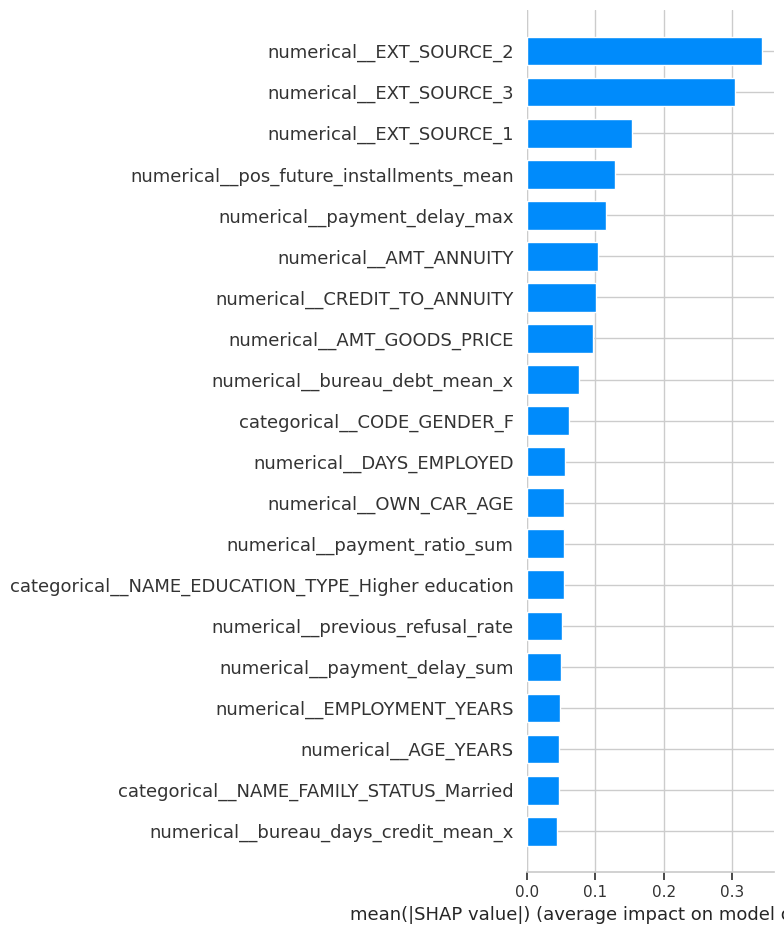

In [475]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

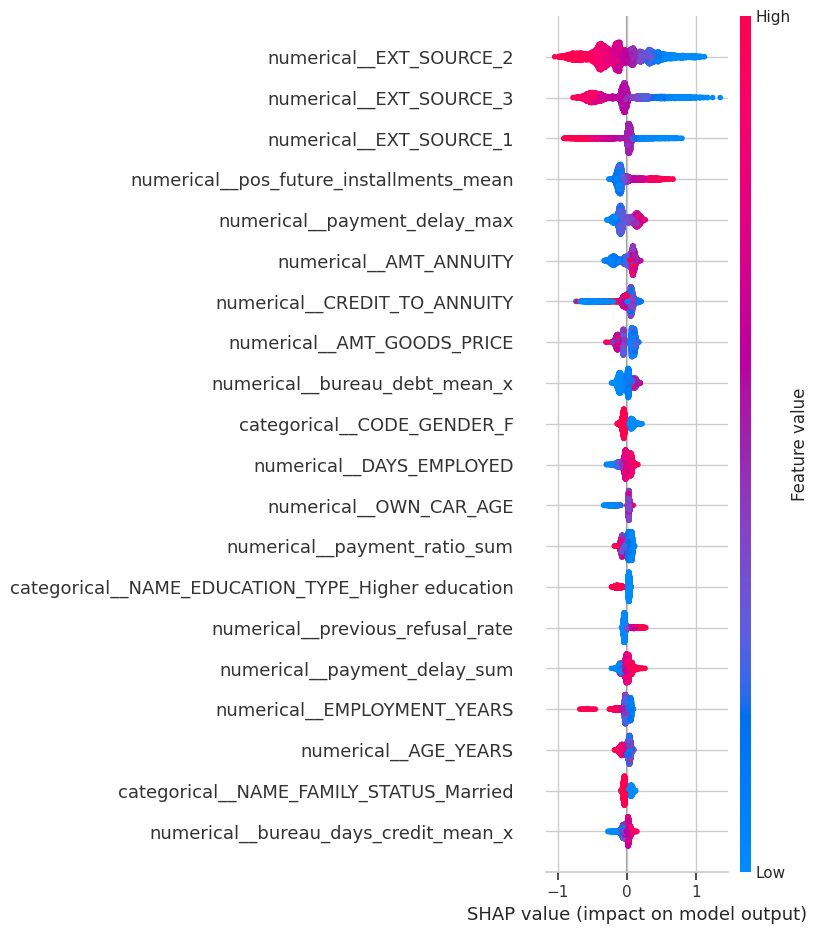

In [476]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names
)

In [477]:
threshold_df.to_csv(
    "/kaggle/working/threshold_analysis.csv",
    index=False
)

pd.DataFrame(
    random_search.cv_results_
).to_csv(
    "/kaggle/working/xgboost_tuning_results.csv",
    index=False
)

In [478]:
print("Final dataset shape:", df.shape)
print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("\nFinal Model Metrics:")
print(final_metrics_df)

print("\nBest XGBoost Parameters:")
print(random_search.best_params_)

print("\nSelected Threshold:")
print(final_threshold)

print("\nTop 10 Features:")
display(feature_importance_df.head(10))

Final dataset shape: (307511, 182)
Training shape: (246008, 180)
Validation shape: (61503, 180)

Final Model Metrics:
      Metric     Value
0    ROC-AUC  0.775977
1     PR-AUC  0.271048
2  Precision  0.207071
3     Recall  0.611078
4         F1  0.309324
5  Threshold  0.550000

Best XGBoost Parameters:
{'classifier__colsample_bytree': np.float64(0.9040922615763338), 'classifier__learning_rate': np.float64(0.056039940157563445), 'classifier__max_depth': 4, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 288, 'classifier__reg_alpha': np.float64(0.9656320330745594), 'classifier__reg_lambda': np.float64(2.1167946962329225), 'classifier__subsample': np.float64(0.7913841307520112)}

Selected Threshold:
0.5500000000000002

Top 10 Features:


,Feature,Importance
0,numerical__EXT_SOURCE_2,0.031087
1,numerical__EXT_SOURCE_3,0.030627
2,numerical__EXT_SOURCE_1,0.014119
3,categorical__NAME_EDUCATION_TYPE_Secondary / s...,0.013741
4,categorical__NAME_EDUCATION_TYPE_Higher education,0.013675
5,categorical__CODE_GENDER_F,0.013043
6,categorical__CODE_GENDER_M,0.010196
7,numerical__FLAG_DOCUMENT_3,0.009827
8,numerical__previous_refusal_rate,0.009672
9,numerical__AGE_YEARS,0.009511
